# Entrega 2 proyecto aprendizaje de máquina

Pedro Pablo Sanín Trujillo (202221527)


## 1 - Carga de datos


In [1]:
# Importar la librerías del proyecto
import pandas as pd
import tensorflow as tf
from keras.layers import TextVectorization
from sklearn.model_selection import train_test_split

In [3]:
# Todo el proyecto vive en repositorios privados de Hugging Face, así que el notebook funciona igual
# en el computador local y en Colab, sin subir ni descargar archivos a mano:
# - REPO_DATOS (dataset): los datos de entrada (train.csv, eval.csv, sample_submission.csv y
#   50_palabras_mas_comunes/), subidos a mano desde huggingface.co, y los submissions que genera el
#   notebook, en la carpeta submissions/.
# - REPO_MODELOS_KERAS: los modelos Keras entrenados (<nombre>.keras y <nombre>_historial.json).
# - <usuario>/proyecto-ml-<nombre_corto>: un repositorio por cada transformer entrenado.
# Se necesita un token con permiso de escritura (https://huggingface.co/settings/tokens). Se pide
# con getpass la primera vez (no queda en el notebook) y después queda guardado en el computador.
from getpass import getpass

from huggingface_hub import HfApi, get_token, hf_hub_download, login

if get_token() is None:
    login(token=getpass("Token de Hugging Face (con permiso de escritura): "))

api = HfApi()
USUARIO_HF = api.whoami()["name"]
REPO_DATOS = f"{USUARIO_HF}/proyecto-ml-datos"
REPO_MODELOS_KERAS = f"{USUARIO_HF}/proyecto-ml-keras"
api.create_repo(REPO_MODELOS_KERAS, private=True, exist_ok=True)

print(f"Sesión de Hugging Face: {USUARIO_HF}")

Carpeta de trabajo: /content
Sesión de Hugging Face: pedropst05


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

datos: ['.cache', '50_palabras_mas_comunes', 'eval.csv', 'sample_submission.csv', 'submission_GRU.csv', 'submission_GRU_mejorado.csv', 'submission_LSTM apiladas.csv', 'submission_LSTM apiladas_mejorado.csv', 'submission_LSTM.csv', 'submission_LSTM_mejorado.csv', 'submission_Simple RNN.csv', 'submission_Simple RNN_mejorado.csv', 'submission_Simple RNNs apiladas.csv', 'submission_Simple RNNs apiladas_mejorado.csv', 'submission_XLM-RoBERTa-Twitter.csv', 'submission_XLM-RoBERTa-Twitter_ultima.csv', 'submission_XLM-RoBERTa.csv', 'submission_mBERT.csv', 'train.csv']
modelos: ['gru_bidireccional_dropout.keras', 'gru_bidireccional_dropout_historial.json', 'gru_bidireccional_dropout_mejorado.keras', 'gru_bidireccional_dropout_mejorado_historial.json', 'lstm.keras', 'lstm_bidireccionales_apiladas.keras', 'lstm_bidireccionales_apiladas_historial.json', 'lstm_bidireccionales_apiladas_mejorado.keras', 'lstm_bidireccionales_apiladas_mejorado_historial.json', 'lstm_historial.json', 'lstm_mejorado.ker

In [75]:
# A continuación, se cargan los conjuntos de datos de entrenamiento y evaluación

# pandas lee directamente del repositorio de Hugging Face con rutas hf://
path_train = f"hf://datasets/{REPO_DATOS}/train.csv"
path_eval = f"hf://datasets/{REPO_DATOS}/eval.csv"


dataset_train_original = pd.read_csv(path_train)
dataset_eval_original = pd.read_csv(path_eval)

dataset_train = dataset_train_original.copy()
dataset_eval = dataset_eval_original.copy()

In [76]:
print(
    f"Número de filas y columnas del conjunto de entrenamiento: {dataset_train.shape}"
)

dataset_train.head(10)

Número de filas y columnas del conjunto de entrenamiento: (20466, 3)


,id,text,label
0,0,Lo pedí un martes por internet y llegó al terc...,negativo
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo
2,2,Lo compré hace como dos meses en una tienda de...,neutral
3,3,Le routeur capte très bien dans toute la maiso...,negativo
4,4,"I got it a while back on sale online, it arriv...",neutral
5,5,Comprei esse teclado mês passado pra trabalhar...,positivo
6,6,Comprei há umas duas semanas pela internet e c...,negativo
7,7,"La compre a mediados de año por internet, tard...",positivo
8,8,Les dejo un comentario rápido. Lo pedí a media...,negativo
9,9,The color accuracy on this monitor is genuinel...,positivo


Vemos que el dataset contiene 20466 filas, cada una con un id, la reseña correspondiente y un label que indica que si la reseña es positiva o negativa. Revisando manualmente algunas entradas, confirmamos que los únicos idiomas presentes en las reseñas son español, inglés, portugués, francés y una mezcla de español e inglés. Esto es consistente con lo indicado en el enunciado del proyecto. Preliminarmente, no separaremos los modelos reseñas por idioma pues esto reduce sustancialmente el tamaño de cada conjunto de datos. Sin embargo, si vale la pena identificar el idioma para tener una división train-test balanceada.

Además nuestra métrica de entrenamiento será el accuracy, de acuerdo con la competencia. A continuación, intentaremos identificar el idioma de cada una de nuestras reseñas.


## 2 - Identificando el idioma de la reseña

Para esto, descargaremos las 50 palabras más comunes en cada uno de los idiomas. Por la ley de Zipf, si las listas de las 50 palabras más comunes son distintas, una de las palabras aparecerá en la lista y esto nos servirá para determinar el idioma de la reseña. Asimismo, las palabras más comunes en cada idioma son artículos y generalmente tienen el mismo significado.

Así, el criterio para determinar el idioma de una reseña será el siguiente:

1. El primer y segundo idioma candidato serán los primeros dos conjuntos de palabras que tengan más coincidencia con las palabras de la reseña.

2. Con las palabras que pertenecen al conjunto más común,


In [77]:
import sys
import unicodedata
from collections import Counter

# Tabla de traducción que reemplaza por un espacio todo carácter Unicode de puntuación
# (categorías 'P*'), lo que incluye ¿ ¡ « » “ ” … además de la puntuación ASCII.
puntua = {
    i: " "
    for i in range(sys.maxunicode + 1)
    if unicodedata.category(chr(i)).startswith("P")
}

# Palabras de la lista de inglés que también son muy comunes en español ("lo he usado"),
# por lo que no cuentan como evidencia de inglés dentro de una reseña en español.
AMBIGUAS_EN = {"he"}


def procesar_resena(text):
    """Pasa la reseña a minúsculas, elimina la puntuación y la separa en palabras."""
    text = text.lower()
    text = text.translate(puntua)
    return text.split()


def palabras_exclusivas(palabras_por_idioma):
    """Para cada idioma, las palabras comunes que no aparecen en la lista de ningún otro idioma."""
    return {
        idioma: palabras
        - set().union(
            *(otras for otro, otras in palabras_por_idioma.items() if otro != idioma)
        )
        for idioma, palabras in palabras_por_idioma.items()
    }


def identificar_idioma(resena, palabras_por_idioma, exclusivas):
    """Identifica el idioma de una reseña: 'es', 'en', 'fr', 'pt_br', 'es_en' (bilingüe) o None.

    1. El idioma principal es el que tiene más ocurrencias de sus palabras exclusivas. Si la reseña
       no tiene ninguna palabra exclusiva, se usan todas las palabras comunes (incluidas las compartidas).
    2. Si el idioma principal es español o inglés y la reseña contiene al menos una palabra exclusiva
       del otro idioma, la reseña se considera bilingüe ('es_en').
    """
    conteo = Counter(procesar_resena(resena))

    def puntajes(listas):
        return {
            idioma: sum(n for palabra, n in conteo.items() if palabra in palabras)
            for idioma, palabras in listas.items()
        }

    puntaje = puntajes(exclusivas)
    if max(puntaje.values()) == 0:
        puntaje = puntajes(palabras_por_idioma)
        if max(puntaje.values()) == 0:
            return None
    principal = max(puntaje, key=lambda k: puntaje[k])

    hay_es = any(palabra in exclusivas["es"] for palabra in conteo)
    hay_en = any(palabra in exclusivas["en"] - AMBIGUAS_EN for palabra in conteo)
    if principal in ("es", "en") and hay_es and hay_en:
        return "es_en"
    return principal

In [78]:
# Cargamos las 50 palabras más comunes por idioma y les aplicamos la misma limpieza que a las reseñas,
# para que entradas como "c'", "l'" o "'s" queden como "c", "l" y "s" y puedan coincidir con las reseñas.
path_palabras = f"hf://datasets/{REPO_DATOS}/50_palabras_mas_comunes/50_palabras_mas_comunes.csv"

palabras_comunes = pd.read_csv(path_palabras)
palabras_comunes["palabra"] = palabras_comunes["palabra"].map(
    lambda p: procesar_resena(p)[0]
)

# Conjunto de palabras por idioma, y el subconjunto de palabras exclusivas de cada idioma
palabras_por_idioma = palabras_comunes.groupby("idioma")["palabra"].apply(set).to_dict()
exclusivas = palabras_exclusivas(palabras_por_idioma)

palabras_comunes.head()

,idioma,rank,palabra,frecuencia
0,en,1,you,28787591
1,en,2,i,27086011
2,en,3,the,22761659
3,en,4,to,17099834
4,en,5,a,14484562


In [79]:
print(
    identificar_idioma("Esta es una reseña de prueba", palabras_por_idioma, exclusivas)
)
print(identificar_idioma("This is a test review", palabras_por_idioma, exclusivas))
print(
    identificar_idioma("Ceci est une critique de test", palabras_por_idioma, exclusivas)
)
print(
    identificar_idioma("Esta é uma crítica de teste", palabras_por_idioma, exclusivas)
)
print(
    identificar_idioma(
        "Esta es una reseña de prueba en inglés: This is a test review",
        palabras_por_idioma,
        exclusivas,
    )
)
print(
    identificar_idioma(
        "Esta es una reseña de prueba en francés: Ceci est une critique de test",
        palabras_por_idioma,
        exclusivas,
    )
)

es
en
fr
pt_br
es_en
es


In [80]:
# Identificamos el idioma de cada reseña de entrenamiento y evaluación
dataset_train["idioma"] = dataset_train["text"].map(
    lambda t: identificar_idioma(t, palabras_por_idioma, exclusivas)
)
dataset_eval["idioma"] = dataset_eval["text"].map(
    lambda t: identificar_idioma(t, palabras_por_idioma, exclusivas)
)

dataset_train["idioma"].value_counts(dropna=False, normalize=True)

,proportion
idioma,
es,0.652497
en,0.114678
pt_br,0.114043
fr,0.102511
es_en,0.016271


In [81]:
dataset_train.head()

,id,text,label,idioma
0,0,Lo pedí un martes por internet y llegó al terc...,negativo,es
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo,es
2,2,Lo compré hace como dos meses en una tienda de...,neutral,es
3,3,Le routeur capte très bien dans toute la maiso...,negativo,fr
4,4,"I got it a while back on sale online, it arriv...",neutral,en


Ahora, dividimos el conjunto de datos en prueba y entrenamiento estratificado para incluir una proporción representativa de cada idioma y de cada etiqueta. Para esto, usaremos `sklearn.train_test_split`.


In [82]:
# Codificamos las etiquetas de como enteros
etiquetas = sorted(
    dataset_train["label"].unique()
)  # ['negativo', 'neutral', 'positivo']
etiqueta_a_id = {e: i for i, e in enumerate(etiquetas)}


# División 90/10 estratificada por idioma y etiqueta a la vez: cada combinación
# (p. ej. "fr|neutral") conserva la misma proporción en entrenamiento y prueba.
estrato = dataset_train["idioma"].astype(str) + "|" + dataset_train["label"]

# train_test_split exige al menos 2 reseñas por estrato. Las combinaciones con una sola
# reseña (solo hay una reseña bilingüe es_en neutral) no se pueden dividir, así que van
# directamente a entrenamiento.
raros = estrato.map(estrato.value_counts()) < 2

train_df, test_df = train_test_split(
    dataset_train[~raros],
    test_size=0.1,
    random_state=42,
    stratify=estrato[~raros],
)
train_df = pd.concat([train_df, dataset_train[raros]])


def dataset_a_tf(df, shuffle):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["text"].values, df["label"].map(etiqueta_a_id).values)
    )
    if shuffle:
        ds = ds.shuffle(len(df), seed=42)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)


train_dataset = dataset_a_tf(train_df, shuffle=True)
test_dataset = dataset_a_tf(test_df, shuffle=False)

## 2 - Red neuronal


In [83]:
encoder_mlp = TextVectorization(output_mode="tf_idf")
encoder_mlp.adapt(train_df["text"])

In [84]:
model_mlp = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(), dtype=tf.string),
        encoder_mlp,
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(3),
    ]
)

model_mlp.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_6            │ (None, 19045)          │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 32)             │       609,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 609,571 (2.33 MB)

 Trainable params: 609,571 (2.33 MB)

 Non-trainable params: 0 (0.00 B)

In [85]:
model_mlp.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"],
)

Ahora para entrenar el modelo, usaremos `tf.keras.callbacks.EarlyStopping`. Esto nos permite parar el entrenamiento cuando la pérdida de validación (`val_loss`) deja de disminuir, y restaurar los parámetros de la época con menor pérdida de validación. Usamos la pérdida y no el accuracy porque el accuracy de validación puede seguir subiendo levemente mientras el modelo ya se está sobreajustando (la pérdida sube porque el modelo se vuelve demasiado confiado en sus errores).


In [4]:
# En lugar de fijar el número de épocas, entrenamos hasta un máximo de 50 y detenemos el
# entrenamiento cuando la métrica `monitor` de validación deja de mejorar durante `patience`
# épocas seguidas. restore_best_weights=True deja el modelo con los pesos de la mejor época.
# Por defecto se monitorea la pérdida de validación ("val_loss"), que se minimiza; si se pasa
# un accuracy (p. ej. monitor="val_accuracy"), se maximiza.
def entrenar_modelo_con_parada_temprana(
    model, train_dataset, test_dataset, max_epochs=50, patience=3, monitor="val_loss"
):
    modo = "min" if "loss" in monitor else "max"
    parada_temprana = tf.keras.callbacks.EarlyStopping(
        monitor=monitor,
        mode=modo,
        patience=patience,
        restore_best_weights=True,
        verbose=1,  # informa en qué época se detuvo y de qué época restauró los pesos
    )

    history = model.fit(
        train_dataset,
        epochs=max_epochs,
        validation_data=test_dataset,
        callbacks=[parada_temprana],
    )

    # Guardamos en el historial la época cuyos pesos restauró la parada temprana (índice desde 0),
    # para que los resúmenes usen exactamente esa época y no la recalculen con otra métrica.
    history.mejor_epoca = parada_temprana.best_epoch
    print(
        f"Mejor época según {monitor}: {history.mejor_epoca + 1} "
        f"(val_loss = {history.history['val_loss'][history.mejor_epoca]:.4f}, "
        f"val_accuracy = {history.history['val_accuracy'][history.mejor_epoca]:.4f})"
    )

    return history


# ---------------------------------------------------------------------------------------------
# Guardado y carga de modelos
# ---------------------------------------------------------------------------------------------
# Cada modelo entrenado se sube a REPO_MODELOS_KERAS como <nombre>.keras (model.save), junto con su
# historial en <nombre>_historial.json. Al volver a ejecutar el notebook, si el modelo ya está en el
# Hub se descarga y se carga con keras.models.load_model en lugar de entrenarlo de nuevo.
# Con REENTRENAR = True se ignoran los modelos guardados y se vuelve a entrenar todo.
import json
import os
import tempfile
from types import SimpleNamespace

from huggingface_hub import CommitOperationAdd

REENTRENAR = False


def historial_a_json(history):
    """Métricas por época y época restaurada por la parada temprana, como bytes JSON."""
    datos = {
        "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
        "mejor_epoca": int(history.mejor_epoca),
    }
    return json.dumps(datos, indent=2).encode()


def descargar_historial(repo, archivo):
    """Devuelve un objeto con `.history` y `.mejor_epoca`, igual que el que devuelve el entrenamiento."""
    with open(hf_hub_download(repo, archivo)) as f:
        datos = json.load(f)
    return SimpleNamespace(history=datos["history"], mejor_epoca=datos["mejor_epoca"])


def resumen_mejor_epoca(history):
    return (
        f"mejor época: {history.mejor_epoca + 1}, "
        f"val_loss = {history.history['val_loss'][history.mejor_epoca]:.4f}, "
        f"val_accuracy = {history.history['val_accuracy'][history.mejor_epoca]:.4f}"
    )


def entrenar_o_cargar(nombre, construir_modelo, train_dataset, test_dataset, **kwargs):
    """Carga el modelo `nombre` de REPO_MODELOS_KERAS si ya está ahí; si no, lo construye con
    `construir_modelo()`, lo entrena con parada temprana (`kwargs` se pasan al entrenamiento) y lo
    sube. Devuelve (modelo, historial)."""
    archivo_modelo = f"{nombre}.keras"
    archivo_historial = f"{nombre}_historial.json"

    if not REENTRENAR and api.file_exists(REPO_MODELOS_KERAS, archivo_historial):
        ruta_modelo = hf_hub_download(REPO_MODELOS_KERAS, archivo_modelo)
        try:
            model = tf.keras.models.load_model(ruta_modelo)
        except Exception as e:
            # Un .keras guardado con una versión de Keras más nueva (p. ej. local) puede traer
            # opciones de configuración que una versión más antigua (p. ej. Colab) no reconoce.
            # Los pesos sí son compatibles: se reconstruye la arquitectura con el código del
            # notebook y se cargan solo los pesos del archivo.
            print(f"load_model falló ({type(e).__name__}); se reconstruye el modelo y se cargan sus pesos")
            model = construir_modelo()
            model.load_weights(ruta_modelo)
        history = descargar_historial(REPO_MODELOS_KERAS, archivo_historial)
        print(f"{nombre} cargado de Hugging Face ({resumen_mejor_epoca(history)})")
        return model, history

    model = construir_modelo()
    history = entrenar_modelo_con_parada_temprana(model, train_dataset, test_dataset, **kwargs)

    with tempfile.TemporaryDirectory() as carpeta:
        ruta_modelo = os.path.join(carpeta, archivo_modelo)
        model.save(ruta_modelo)
        # Un solo commit con los dos archivos; el historial es el que marca que el modelo está completo
        api.create_commit(
            REPO_MODELOS_KERAS,
            operations=[
                CommitOperationAdd(archivo_modelo, ruta_modelo),
                CommitOperationAdd(archivo_historial, historial_a_json(history)),
            ],
            commit_message=f"Modelo {nombre}",
        )
    print(f"{nombre} subido a https://huggingface.co/{REPO_MODELOS_KERAS}")
    return model, history

In [87]:
model_mlp, historial_mlp = entrenar_o_cargar(
    "mlp_tfidf", lambda: model_mlp, train_dataset, test_dataset
)

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/mlp_tfidf.keras (mejor época: 1, val_loss = 0.5202, val_accuracy = 0.6771)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


### 3.1 - Búsqueda de hiperparámetros


## 3 - Red neuronal recurrente básica


Inicialmente, usaremos una red neuronal recurrente para clasificar las reseñas. Inicialmente, veremos el desempeño de una RNN simple, donde cada neurona tiene información sobre las operaciones que ha hecho en pasos anteriores. Las redes neuronales recurrentes funcionan bien al procesar lenguaje natural pues el lenguaje tiene una naturaleza secuencial.

Usaremos la implementación de RNNs dada por `tf.keras.layers.SimpleRNN`. Para que el texto pueda pasar exitosamente por una red neuronal, debemos vectorizarlo. Para esto, usaremos una capa inicial de la red neuronal dada por `tf.keras.layers.TextVectorization`. Este algoritmo de vectorización combina varias formas de vectorizar frases como _tf_idf_, _count_ (bag of words) y soporta ngramas.


In [88]:
# Para una red recurrente necesitamos una secuencia de índices de palabras (output_mode='int'),
# no un vector tf_idf. Cada reseña se rellena o recorta a 100 palabras (mediana: 57, máximo: 125).


# Tildes a quitar (unicodedata no sirve aquí porque Keras pasa tensores, no str,
# y TensorFlow no trae normalización Unicode sin el paquete tensorflow_text).
TILDES = {
    "[áàâäã]": "a",
    "[éèêë]": "e",
    "[íìîï]": "i",
    "[óòôöõ]": "o",
    "[úùûü]": "u",
    "ñ": "n",
    "ç": "c",
}


# Registrar la función permite guardar el TextVectorization en .keras y volver a cargarlo.
@tf.keras.utils.register_keras_serializable(package="proyecto")
def standardize_text(text):
    text = tf.strings.lower(text, encoding="utf-8")
    text = tf.strings.regex_replace(text, "<br />", " ")
    for patron, letra in TILDES.items():
        text = tf.strings.regex_replace(text, patron, letra)
    text = tf.strings.regex_replace(text, "[^a-z']", " ")
    return text


def crear_encoder_rnn(train_df, n_gram=1):

    encoder_rnn = TextVectorization(
        output_mode="int",
        output_sequence_length=100,
        standardize=standardize_text,
        ngrams=n_gram,  # pyright: ignore[reportArgumentType]
    )
    encoder_rnn.adapt(train_df["text"])
    return encoder_rnn


encoder_rnn = crear_encoder_rnn(train_df)

texto_original = train_df["text"].iloc[0]
texto_vectorizado = encoder_rnn(tf.convert_to_tensor([texto_original]))

encoder_rnn = crear_encoder_rnn(train_df)

texto_original = train_df["text"][1]
texto_vectorizado = encoder_rnn(tf.convert_to_tensor([texto_original]))
print(f"Texto original: {texto_original}")
print(f"Texto vectorizado: {texto_vectorizado}")

Texto original: Les cuento como me fue. Compre esta tablet a mediados de año y llego en cuatro dias a mi casa en Guadalajara, sin ningun problema con el paquete. En mi opinion, la resolucion me resulto ser deficiente para ser honesto. La uso sobre todo por las tardes para revisar correos y ver videos mientras ceno. La pantalla tactil termino siendo muy buena en el uso real.
Texto vectorizado: [[  82  687   69   10  185   18   76 1860    6   70    3  104    9   13
     4   52   12    6   20   24    4  417   42  746  150   19    5   95
     4   20  435    2  530   10   71  107  998   14  107  437    2   23
   147   53   15   36  163   14  732 1686    9  496  938  356 7770    2
   270  570  195  219  172  481    4    5   23  378    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0]]


Ahora, entrenaremos una red neuronal con una capa de embedding, una capa SimpleRNN de 64 neuronas y una capa oculta densa de 32 neuronas con función de activación ReLU. Asimismo, entrenamos un embedding con una dimensión de salida de 64.


In [89]:
model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(), dtype=tf.string),
        encoder_rnn,
        tf.keras.layers.Embedding(
            input_dim=encoder_rnn.vocabulary_size(), output_dim=64, mask_zero=True
        ),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(3),
    ]
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_12 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_11 (SimpleRNN)       │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,137,539 (4.34 MB)

 Trainable params: 1,137,539 (4.34 MB)

 Non-trainable params: 0 (0.00 B)

In [90]:
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [91]:
model, historial_simplernn = entrenar_o_cargar(
    "simplernn", lambda: model, train_dataset, test_dataset
)

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/simplernn.keras (mejor época: 2, val_loss = 0.4717, val_accuracy = 0.7592)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


### 2.1 - Probando diferentes combinaciones de capas

A continuación, probaremos 5 combinaciones distintas de capas para determinar cual tiene mejor desempeño en validación.


Para no repetir código, definimos una función que arma la red con la misma estructura de la celda anterior
(entrada de texto → `encoder_rnn` → `Embedding` → **capas recurrentes** → `Dense(32, relu)` → `Dense(3)`)
y solo cambia el bloque de capas recurrentes. Cada modelo tiene su propia capa de embedding, de modo que
ninguno comparte pesos entrenables con otro; `encoder_rnn` sí se comparte, pero no tiene pesos entrenables.


In [92]:
def construir_modelo_rnn(capas_recurrentes, nombre):
    """Arma y compila una red recurrente cuyo bloque central son las capas recibidas."""
    model = tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(), dtype=tf.string),
            encoder_rnn,
            tf.keras.layers.Embedding(
                input_dim=encoder_rnn.vocabulary_size(), output_dim=64, mask_zero=True
            ),
            *capas_recurrentes,
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(3),
        ],
        name=nombre,
    )
    model.compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=tf.keras.optimizers.Adam(),
        metrics=["accuracy"],
    )
    return model


# Guardamos el historial de entrenamiento de cada combinación para compararlas al final
historiales = {}

#### Modelo 1 - SimpleRNN bidireccional

La misma `SimpleRNN(64)` del modelo base, pero envuelta en `Bidirectional`: una copia lee la reseña de
izquierda a derecha y otra de derecha a izquierda, y sus salidas se concatenan. Así, la representación final
no depende solo de las últimas palabras de la reseña.


In [93]:
model_rnn_1, historiales["1 - SimpleRNN bidireccional"] = entrenar_o_cargar(
    "simplernn_bidireccional",
    lambda: construir_modelo_rnn(
        [tf.keras.layers.Bidirectional(tf.keras.layers.SimpleRNN(64))],
        nombre="simplernn_bidireccional",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_1.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/simplernn_bidireccional.keras (mejor época: 1, val_loss = 0.4801, val_accuracy = 0.7352)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "simplernn_bidireccional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_13 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_12                │ (None, 128)            │        16,512 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,147,843 (4.38 MB)

 Trainable params: 1,147,843 (4.38 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 2 - Dos SimpleRNN apiladas

Dos capas `SimpleRNN` apiladas (64 y 32 neuronas). La primera usa `return_sequences=True` para entregarle a la
segunda la salida de cada paso de tiempo, no solo la del último.


In [94]:
model_rnn_2, historiales["2 - SimpleRNN apiladas"] = entrenar_o_cargar(
    "simplernn_apiladas",
    lambda: construir_modelo_rnn(
        [
            tf.keras.layers.SimpleRNN(64, return_sequences=True),
            tf.keras.layers.SimpleRNN(32),
        ],
        nombre="simplernn_apiladas",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_2.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/simplernn_apiladas.keras (mejor época: 2, val_loss = 0.4176, val_accuracy = 0.7782)


Model: "simplernn_apiladas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_14 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_13 (SimpleRNN)       │ (None, 100, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_14 (SimpleRNN)       │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,139,619 (4.35 MB)

 Trainable params: 1,139,619 (4.35 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 3 - LSTM

Reemplazamos la `SimpleRNN` por una `LSTM(64)`. Sus compuertas de entrada, olvido y salida le permiten conservar
información a lo largo de secuencias largas y mitigan el desvanecimiento del gradiente de la RNN simple.


In [95]:
model_rnn_3, historiales["3 - LSTM"] = entrenar_o_cargar(
    "lstm",
    lambda: construir_modelo_rnn(
        [tf.keras.layers.LSTM(64)],
        nombre="lstm",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_3.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/lstm.keras (mejor época: 2, val_loss = 0.3495, val_accuracy = 0.8002)


Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_15 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,162,307 (4.43 MB)

 Trainable params: 1,162,307 (4.43 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 4 - GRU bidireccional con dropout

Una `GRU(64)` bidireccional (similar a la LSTM pero con menos parámetros) seguida de un `Dropout(0.5)` para
regularizar, ya que con alrededor de 18.000 reseñas de entrenamiento los modelos se sobreajustan con facilidad.


In [96]:
model_rnn_4, historiales["4 - GRU bidireccional + dropout"] = entrenar_o_cargar(
    "gru_bidireccional_dropout",
    lambda: construir_modelo_rnn(
        [
            tf.keras.layers.Bidirectional(tf.keras.layers.GRU(64)),
            tf.keras.layers.Dropout(0.5),
        ],
        nombre="gru_bidireccional_dropout",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_4.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/gru_bidireccional_dropout.keras (mejor época: 2, val_loss = 0.3305, val_accuracy = 0.8144)


Model: "gru_bidireccional_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_16 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_13                │ (None, 128)            │        49,920 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,181,251 (4.51 MB)

 Trainable params: 1,181,251 (4.51 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 5 - Dos LSTM bidireccionales apiladas con dropout

La combinación más profunda: dos `LSTM` bidireccionales apiladas (64 y 32 neuronas), con `Dropout(0.3)` entre ellas
y `Dropout(0.5)` antes de las capas densas.


In [97]:
model_rnn_5, historiales["5 - LSTM bidireccionales apiladas"] = entrenar_o_cargar(
    "lstm_bidireccionales_apiladas",
    lambda: construir_modelo_rnn(
        [
            tf.keras.layers.Bidirectional(
                tf.keras.layers.LSTM(64, return_sequences=True)
            ),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)),
            tf.keras.layers.Dropout(0.5),
        ],
        nombre="lstm_bidireccionales_apiladas",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_5.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/lstm_bidireccionales_apiladas.keras (mejor época: 3, val_loss = 0.3513, val_accuracy = 0.8046)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 36 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "lstm_bidireccionales_apiladas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_17 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_14                │ (None, 100, 128)       │        66,048 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_15                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,236,547 (4.72 MB)

 Trainable params: 1,236,547 (4.72 MB)

 Non-trainable params: 0 (0.00 B)

#### Creación de archivos submission


In [98]:
# Métricas de la época que restauró la parada temprana (la de menor val_loss)
resumen_rnn = pd.DataFrame(
    [
        {
            "modelo": nombre,
            "mejor_epoca": h.mejor_epoca + 1,
            "val_loss": h.history["val_loss"][h.mejor_epoca],
            "val_accuracy": h.history["val_accuracy"][h.mejor_epoca],
            "train_accuracy": h.history["accuracy"][h.mejor_epoca],
        }
        for nombre, h in historiales.items()
    ]
).sort_values("val_accuracy", ascending=False)

resumen_rnn

,modelo,mejor_epoca,val_loss,val_accuracy,train_accuracy
3,4 - GRU bidireccional + dropout,2,0.330486,0.814362,0.822955
4,5 - LSTM bidireccionales apiladas,3,0.351309,0.804592,0.834464
2,3 - LSTM,2,0.349475,0.800195,0.846354
1,2 - SimpleRNN apiladas,2,0.417577,0.778212,0.820186
0,1 - SimpleRNN bidireccional,1,0.480135,0.735222,0.645203


In [99]:
def crear_archivo_predicciones(
    model, df, archivo_salida="submission.csv", columnas=("text",)
):
    """Predice la etiqueta de cada reseña de `df` y sube a REPO_DATOS, en submissions/<archivo_salida>,
    un CSV con el formato de sample_submission.csv: columnas `id` y `answer` ('negativo', 'neutral'
    o 'positivo').

    `columnas` son las columnas de `df` que recibe el modelo: con una sola (por defecto "text")
    se le pasan los textos directamente; con varias, un dict {nombre_columna: textos}, que es lo
    que esperan los modelos de dos entradas de la sección 3.2."""
    if len(columnas) == 1:
        entradas = df[columnas[0]].values
    else:
        entradas = {c: df[c].values for c in columnas}
    textos = tf.data.Dataset.from_tensor_slices(entradas).batch(32)

    # El modelo devuelve logits (una fila de 3 valores por reseña): la clase predicha es la de
    # mayor logit, y la traducimos de vuelta a texto con la misma lista usada al codificarlas.
    logits = model.predict(textos)
    clases = logits.argmax(axis=1)

    submission = pd.DataFrame(
        {"id": df["id"].values, "answer": [etiquetas[c] for c in clases]}
    )
    api.upload_file(
        path_or_fileobj=submission.to_csv(index=False).encode(),
        path_in_repo=f"submissions/{archivo_salida}",
        repo_id=REPO_DATOS,
        repo_type="dataset",
        commit_message=f"Submission {archivo_salida}",
    )

    print(
        f"{archivo_salida} subido a https://huggingface.co/datasets/{REPO_DATOS}/tree/main/submissions "
        f"({len(submission)} predicciones)"
    )
    print(submission["answer"].value_counts(normalize=True))
    return submission

In [100]:
# Cambiar por el modelo con mejor val_accuracy
modelos_rnn = [model_rnn_1, model_rnn_2, model_rnn_3, model_rnn_4, model_rnn_5]
nombres_modelo = ["Simple RNN", "Simple RNNs apiladas", "LSTM", "GRU", "LSTM apiladas"]
modelos_rnn = {"nombre": nombres_modelo, "modelo": modelos_rnn}

for nombre, modelo in zip(modelos_rnn["nombre"], modelos_rnn["modelo"]):
    submission = crear_archivo_predicciones(
        modelo, dataset_eval, f"submission_{nombre}.csv"
    )
    submission.head()

212/212 ━━━━━━━━━━━━━━━━━━━━ 18s 81ms/step
Archivo guardado en ./datos/submission_Simple RNN.csv (6781 predicciones)
answer
negativo    0.527503
positivo    0.274148
neutral     0.198348
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 22s 102ms/step
Archivo guardado en ./datos/submission_Simple RNNs apiladas.csv (6781 predicciones)
answer
positivo    0.451556
negativo    0.348621
neutral     0.199823
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Archivo guardado en ./datos/submission_LSTM.csv (6781 predicciones)
answer
negativo    0.420439
positivo    0.391978
neutral     0.187583
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Archivo guardado en ./datos/submission_GRU.csv (6781 predicciones)
answer
negativo    0.414098
positivo    0.395812
neutral     0.190090
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step
Archivo guardado en ./datos/submission_LSTM apiladas.csv (6781 predicciones)
answer


### 3.2 - Ajustando y regularizando los modelos RNN

En el proyecto anterior, la última oración era la que más significado daba a la reseña completa. Para esto, agregabamos la última oración como una entrada adicional al modelo. En este caso, haremos lo mismo.

Asimismo, vemos que los modelos que estamos usando tienden al overfitting. Para solucionar esto intentaremos pararemos el entrenamiento en las epochs en función de la función de pérdida y no el accuracy en el entrenamiento. De esta forma, el modelo elegido no se elige de acuerdo a los datos específicos de entrenamiento.

También, intentaremos regularizar más las RNNs. Para esto, usaremos `SpatialDropout1D` después del embedding. A diferencia de `Dropout`, `SpatialDropout1D` hace dropout para columnas enteras del espacio, lo que aumenta la regularización.


In [101]:
import re


def ultima_oracion(texto):
    """Devuelve la última oración de la reseña (corta después de . ! ?)."""
    oraciones = [o for o in re.split(r"(?<=[.!?])\s+", texto.strip()) if o]
    return oraciones[-1] if oraciones else texto


# .assign crea un DataFrame nuevo y evita el SettingWithCopyWarning
train_df = train_df.assign(ultima=train_df["text"].map(ultima_oracion))
test_df = test_df.assign(ultima=test_df["text"].map(ultima_oracion))
dataset_eval = dataset_eval.assign(ultima=dataset_eval["text"].map(ultima_oracion))


def entradas_modelo(df, columnas):
    """Una columna -> arreglo de textos (como antes); varias -> dict {nombre_columna: textos}."""
    if len(columnas) == 1:
        return df[columnas[0]].values
    return {c: df[c].values for c in columnas}


def dataset_a_tf(df, shuffle, columnas=("text",)):
    ds = tf.data.Dataset.from_tensor_slices(
        (entradas_modelo(df, columnas), df["label"].map(etiqueta_a_id).values)
    )
    if shuffle:
        ds = ds.shuffle(len(df), seed=42)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)


train_dataset = dataset_a_tf(train_df, shuffle=True)
test_dataset = dataset_a_tf(test_df, shuffle=False)

Para comparar de forma justa, cada modelo mejorado conserva exactamente el bloque recurrente de su
modelo original de la sección 2.1. Solo cambian dos cosas:

1. Una segunda entrada con la última oración de la reseña, procesada por su propia copia del bloque recurrente.
2. `SpatialDropout1D(0.3)` después del embedding.

La parada temprana según `val_loss` ya no es una diferencia entre ambos grupos: `entrenar_modelo_con_parada_temprana`
la usa por defecto, así que los modelos originales también se eligen con la pérdida de validación.


In [102]:
def construir_modelo_rnn_mejorado(
    crear_capas_recurrentes, nombre, tasa_spatial_dropout=0.3
):
    """Igual que `construir_modelo_rnn`, pero con las mejoras de esta sección:

    - Dos entradas: la reseña completa (`text`) y su última oración (`ultima`). Cada una pasa
      por su propia copia del bloque recurrente y las dos salidas se concatenan antes de las
      capas densas.
    - `SpatialDropout1D` justo después del embedding, en ambas ramas.

    `crear_capas_recurrentes` es una función que devuelve una lista NUEVA de capas cada vez que se
    llama, para que cada rama tenga sus propios pesos (si se usaran las mismas capas en las dos
    ramas, Keras compartiría sus pesos). El embedding sí se comparte entre ambas ramas, de modo
    que las palabras de la última oración también aprenden de la reseña completa.
    """
    embedding = tf.keras.layers.Embedding(
        input_dim=encoder_rnn.vocabulary_size(), output_dim=64, mask_zero=True
    )

    def rama(entrada):
        x = embedding(encoder_rnn(entrada))
        x = tf.keras.layers.SpatialDropout1D(tasa_spatial_dropout)(x)
        for capa in crear_capas_recurrentes():
            x = capa(x)
        return x

    # Los nombres de los Input coinciden con las columnas del DataFrame (las claves del dict)
    texto = tf.keras.layers.Input(shape=(), dtype=tf.string, name="text")
    ultima = tf.keras.layers.Input(shape=(), dtype=tf.string, name="ultima")

    x = tf.keras.layers.Concatenate()([rama(texto), rama(ultima)])
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    salida = tf.keras.layers.Dense(3)(x)

    model = tf.keras.Model([texto, ultima], salida, name=nombre)
    model.compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=tf.keras.optimizers.Adam(),
        metrics=["accuracy"],
    )
    return model


# Conjuntos de datos con las dos entradas: reseña completa y última oración
columnas_2 = ("text", "ultima")
train_dataset_2 = dataset_a_tf(train_df, shuffle=True, columnas=columnas_2)
test_dataset_2 = dataset_a_tf(test_df, shuffle=False, columnas=columnas_2)

# Usamos las mismas claves que en `historiales` para poder comparar cada modelo con su original
historiales_mejorados = {}

#### Modelo 1 mejorado - SimpleRNN bidireccional

Mismo bloque recurrente que el modelo 1: una `SimpleRNN(64)` bidireccional.


In [103]:
model_rnn_1_mejorado, historiales_mejorados["1 - SimpleRNN bidireccional"] = (
    entrenar_o_cargar(
        "simplernn_bidireccional_mejorado",
        lambda: construir_modelo_rnn_mejorado(
            lambda: [tf.keras.layers.Bidirectional(tf.keras.layers.SimpleRNN(64))],
            nombre="simplernn_bidireccional_mejorado",
        ),
        train_dataset_2,
        test_dataset_2,
        monitor="val_loss",
    )
)
model_rnn_1_mejorado.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/simplernn_bidireccional_mejorado.keras (mejor época: 1, val_loss = 0.4822, val_accuracy = 0.7655)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 36 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "simplernn_bidireccional_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_18        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_18[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_35        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_18[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_36        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_16    │ (None, 128)       │     16,512 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_35[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_17    │ (None, 128)       │     16,512 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_36[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 256)       │          0 │ bidirectional_16… │
│ (Concatenate)       │                   │            │ bidirectional_17… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_42 (Dense)    │ (None, 32)        │      8,224 │ concatenate_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_43 (Dense)    │ (None, 3)         │         99 │ dense_42[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,168,451 (4.46 MB)

 Trainable params: 1,168,451 (4.46 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 2 mejorado - Dos SimpleRNN apiladas

Mismo bloque recurrente que el modelo 2: `SimpleRNN(64, return_sequences=True)` seguida de `SimpleRNN(32)`.


In [104]:
model_rnn_2_mejorado, historiales_mejorados["2 - SimpleRNN apiladas"] = (
    entrenar_o_cargar(
        "simplernn_apiladas_mejorado",
        lambda: construir_modelo_rnn_mejorado(
            lambda: [
                tf.keras.layers.SimpleRNN(64, return_sequences=True),
                tf.keras.layers.SimpleRNN(32),
            ],
            nombre="simplernn_apiladas_mejorado",
        ),
        train_dataset_2,
        test_dataset_2,
        monitor="val_loss",
    )
)
model_rnn_2_mejorado.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/simplernn_apiladas_mejorado.keras (mejor época: 2, val_loss = 0.4766, val_accuracy = 0.7445)


Model: "simplernn_apiladas_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_19        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_19[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_37        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_19[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_38        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_17       │ (None, 100, 64)   │      8,256 │ spatial_dropout1… │
│ (SimpleRNN)         │                   │            │ not_equal_37[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_19       │ (None, 100, 64)   │      8,256 │ spatial_dropout1… │
│ (SimpleRNN)         │                   │            │ not_equal_38[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_18       │ (None, 32)        │      3,104 │ simple_rnn_17[0]… │
│ (SimpleRNN)         │                   │            │ not_equal_37[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_20       │ (None, 32)        │      3,104 │ simple_rnn_19[0]… │
│ (SimpleRNN)         │                   │            │ not_equal_38[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 64)        │          0 │ simple_rnn_18[0]… │
│ (Concatenate)       │                   │            │ simple_rnn_20[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_44 (Dense)    │ (None, 32)        │      2,080 │ concatenate_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_45 (Dense)    │ (None, 3)         │         99 │ dense_44[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,152,003 (4.39 MB)

 Trainable params: 1,152,003 (4.39 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 3 mejorado - LSTM

Mismo bloque recurrente que el modelo 3: una `LSTM(64)`.


In [105]:
model_rnn_3_mejorado, historiales_mejorados["3 - LSTM"] = entrenar_o_cargar(
    "lstm_mejorado",
    lambda: construir_modelo_rnn_mejorado(
        lambda: [tf.keras.layers.LSTM(64)],
        nombre="lstm_mejorado",
    ),
    train_dataset_2,
    test_dataset_2,
    monitor="val_loss",
)
model_rnn_3_mejorado.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/lstm_mejorado.keras (mejor época: 2, val_loss = 0.3595, val_accuracy = 0.7914)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "lstm_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_20        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_20[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_39        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_20[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_40        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_12 (LSTM)      │ (None, 64)        │     33,024 │ spatial_dropout1… │
│                     │                   │            │ not_equal_39[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_13 (LSTM)      │ (None, 64)        │     33,024 │ spatial_dropout1… │
│                     │                   │            │ not_equal_40[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 128)       │          0 │ lstm_12[0][0],    │
│ (Concatenate)       │                   │            │ lstm_13[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_46 (Dense)    │ (None, 32)        │      4,128 │ concatenate_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_47 (Dense)    │ (None, 3)         │         99 │ dense_46[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,197,379 (4.57 MB)

 Trainable params: 1,197,379 (4.57 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 4 mejorado - GRU bidireccional con dropout

Mismo bloque recurrente que el modelo 4: una `GRU(64)` bidireccional seguida de `Dropout(0.5)`.


In [106]:
model_rnn_4_mejorado, historiales_mejorados["4 - GRU bidireccional + dropout"] = (
    entrenar_o_cargar(
        "gru_bidireccional_dropout_mejorado",
        lambda: construir_modelo_rnn_mejorado(
            lambda: [
                tf.keras.layers.Bidirectional(tf.keras.layers.GRU(64)),
                tf.keras.layers.Dropout(0.5),
            ],
            nombre="gru_bidireccional_dropout_mejorado",
        ),
        train_dataset_2,
        test_dataset_2,
        monitor="val_loss",
    )
)
model_rnn_4_mejorado.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/gru_bidireccional_dropout_mejorado.keras (mejor época: 2, val_loss = 0.3439, val_accuracy = 0.8007)


Model: "gru_bidireccional_dropout_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_21        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_21[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_41        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_21[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_42        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_18    │ (None, 128)       │     49,920 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_41[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_19    │ (None, 128)       │     49,920 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_42[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 128)       │          0 │ bidirectional_18… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 128)       │          0 │ bidirectional_19… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 256)       │          0 │ dropout_12[0][0], │
│ (Concatenate)       │                   │            │ dropout_13[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_48 (Dense)    │ (None, 32)        │      8,224 │ concatenate_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_49 (Dense)    │ (None, 3)         │         99 │ dense_48[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,235,267 (4.71 MB)

 Trainable params: 1,235,267 (4.71 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 5 mejorado - Dos LSTM bidireccionales apiladas con dropout

Mismo bloque recurrente que el modelo 5: dos `LSTM` bidireccionales apiladas (64 y 32 neuronas) con `Dropout(0.3)` entre ellas y `Dropout(0.5)` al final.


In [107]:
model_rnn_5_mejorado, historiales_mejorados["5 - LSTM bidireccionales apiladas"] = (
    entrenar_o_cargar(
        "lstm_bidireccionales_apiladas_mejorado",
        lambda: construir_modelo_rnn_mejorado(
            lambda: [
                tf.keras.layers.Bidirectional(
                    tf.keras.layers.LSTM(64, return_sequences=True)
                ),
                tf.keras.layers.Dropout(0.3),
                tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)),
                tf.keras.layers.Dropout(0.5),
            ],
            nombre="lstm_bidireccionales_apiladas_mejorado",
        ),
        train_dataset_2,
        test_dataset_2,
        monitor="val_loss",
    )
)
model_rnn_5_mejorado.summary()

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos
Modelo cargado de ./modelos/lstm_bidireccionales_apiladas_mejorado.keras (mejor época: 2, val_loss = 0.3436, val_accuracy = 0.7938)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 60 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "lstm_bidireccionales_apiladas_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_22        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_22[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_43        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_22[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_44        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_20    │ (None, 100, 128)  │     66,048 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_43[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_22    │ (None, 100, 128)  │     66,048 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_44[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 100, 128)  │          0 │ bidirectional_20… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 100, 128)  │          0 │ bidirectional_22… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_21    │ (None, 64)        │     41,216 │ dropout_14[0][0], │
│ (Bidirectional)     │                   │            │ not_equal_43[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_23    │ (None, 64)        │     41,216 │ dropout_16[0][0], │
│ (Bidirectional)     │                   │            │ not_equal_44[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 64)        │          0 │ bidirectional_21… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_17          │ (None, 64)        │          0 │ bidirectional_23… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 128)       │          0 │ dropout_15[0][0], │
│ (Concatenate)       │                   │            │ dropout_17[0][0]  │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,345,859 (5.13 MB)

 Trainable params: 1,345,859 (5.13 MB)

 Non-trainable params: 0 (0.00 B)

#### Comparación con los modelos originales

Para cada modelo tomamos las métricas de la época que restauró la parada temprana. Tanto en los originales como
en los mejorados esa época se eligió con `val_loss`, así que el `val_accuracy` reportado no está sesgado por la
selección y ambos grupos se comparan en igualdad de condiciones. Con ~2.000 reseñas de validación, el error estándar
del accuracy es de casi 1 punto, así que diferencias menores a eso no son concluyentes.


In [108]:
def resumir_historiales(historiales):
    """Una fila por modelo con las métricas de la época restaurada por la parada temprana."""
    filas = []
    for nombre, h in historiales.items():
        mejor = h.mejor_epoca
        filas.append(
            {
                "modelo": nombre,
                "mejor_epoca": mejor + 1,
                "val_accuracy": h.history["val_accuracy"][mejor],
                "val_loss": h.history["val_loss"][mejor],
                "train_accuracy": h.history["accuracy"][mejor],
            }
        )
    return pd.DataFrame(filas)


comparacion = resumir_historiales(historiales).merge(
    resumir_historiales(historiales_mejorados),
    on="modelo",
    suffixes=("_original", "_mejorado"),
)
comparacion["diferencia_val_accuracy"] = (
    comparacion["val_accuracy_mejorado"] - comparacion["val_accuracy_original"]
)

comparacion[
    [
        "modelo",
        "mejor_epoca_original",
        "mejor_epoca_mejorado",
        "val_loss_original",
        "val_loss_mejorado",
        "val_accuracy_original",
        "val_accuracy_mejorado",
        "diferencia_val_accuracy",
        "train_accuracy_original",
        "train_accuracy_mejorado",
    ]
].sort_values("val_accuracy_mejorado", ascending=False)

,modelo,mejor_epoca_original,mejor_epoca_mejorado,val_loss_original,val_loss_mejorado,val_accuracy_original,val_accuracy_mejorado,diferencia_val_accuracy,train_accuracy_original,train_accuracy_mejorado
3,4 - GRU bidireccional + dropout,2,2,0.330486,0.343948,0.814362,0.800684,-0.013679,0.822955,0.829307
4,5 - LSTM bidireccionales apiladas,3,2,0.351309,0.343551,0.804592,0.793845,-0.010747,0.834464,0.826646
2,3 - LSTM,2,2,0.349475,0.359451,0.800195,0.791402,-0.008793,0.846354,0.825343
0,1 - SimpleRNN bidireccional,1,1,0.480135,0.482226,0.735222,0.765510,0.030288,0.645203,0.644552
1,2 - SimpleRNN apiladas,2,2,0.417577,0.476619,0.778212,0.744504,-0.033708,0.820186,0.774743


In [109]:
# Archivos submission de los modelos mejorados (reciben la reseña y su última oración)
modelos_mejorados = {
    "Simple RNN": model_rnn_1_mejorado,
    "Simple RNNs apiladas": model_rnn_2_mejorado,
    "LSTM": model_rnn_3_mejorado,
    "GRU": model_rnn_4_mejorado,
    "LSTM apiladas": model_rnn_5_mejorado,
}

for nombre, modelo in modelos_mejorados.items():
    crear_archivo_predicciones(
        modelo,
        dataset_eval,
        f"submission_{nombre}_mejorado.csv",
        columnas=columnas_2,
    )

212/212 ━━━━━━━━━━━━━━━━━━━━ 30s 138ms/step
Archivo guardado en ./datos/submission_Simple RNN_mejorado.csv (6781 predicciones)
answer
negativo    0.428698
positivo    0.347441
neutral     0.223861
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 32s 147ms/step
Archivo guardado en ./datos/submission_Simple RNNs apiladas_mejorado.csv (6781 predicciones)
answer
negativo    0.441528
positivo    0.365728
neutral     0.192744
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
Archivo guardado en ./datos/submission_LSTM_mejorado.csv (6781 predicciones)
answer
negativo    0.415131
positivo    0.378705
neutral     0.206164
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step
Archivo guardado en ./datos/submission_GRU_mejorado.csv (6781 predicciones)
answer
positivo    0.468662
negativo    0.342280
neutral     0.189058
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step
Archivo guardado en ./datos/submission_LSTM ap

Vemos entonces que estas estrategias de regularización no funcionaron.


### 3.3 - Identificación del error

Para entender en qué se equivocan las RNN, analizamos sobre `test_df` el modelo con mejor `val_accuracy` de las
secciones 3.1 y 3.2:

1. Precisión, recall y F1 de cada clase.
2. La matriz de confusión normalizada por fila: qué fracción de las reseñas de cada clase real termina en cada
   clase predicha.
3. El accuracy por idioma, usando la columna `idioma` de la sección 2.
4. Una muestra de reseñas mal clasificadas, para leerlas completas.

`identificar_errores` solo recibe las clases predichas, así que la reutilizamos tal cual con mBERT en la sección 4.


In [110]:
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, classification_report


def identificar_errores(clases, df, nombre, n_ejemplos=10):
    """Analiza las predicciones `clases` (0, 1 o 2) sobre `df` y devuelve las reseñas mal clasificadas."""
    reales = df["label"].map(etiqueta_a_id).values

    print(classification_report(reales, clases, target_names=etiquetas, digits=3))

    ConfusionMatrixDisplay.from_predictions(
        reales,
        clases,
        display_labels=etiquetas,
        normalize="true",  # cada fila suma 1
        values_format=".2f",
        cmap="Blues",
    )
    plt.title(f"Matriz de confusión - {nombre}")
    plt.xlabel("Clase predicha")
    plt.ylabel("Clase real")
    plt.show()

    resultados = df.assign(
        idioma=df["idioma"].astype(str),
        prediccion=[etiquetas[c] for c in clases],
        acierto=clases == reales,
    )
    display(
        resultados.groupby("idioma")["acierto"]
        .agg(accuracy="mean", resenas="size")
        .sort_values("accuracy")
    )

    errores = resultados.loc[
        ~resultados["acierto"], ["idioma", "label", "prediccion", "text"]
    ]
    print(f"{len(errores)} de {len(df)} reseñas mal clasificadas. Algunas de ellas:")
    with pd.option_context("display.max_colwidth", None):
        display(errores.sample(min(n_ejemplos, len(errores)), random_state=42))
    return errores

Mejor RNN: 4 - GRU bidireccional + dropout
 1/64 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
              precision    recall  f1-score   support

    negativo      0.748     0.756     0.752       738
     neutral      0.986     0.980     0.983       560
    positivo      0.753     0.748     0.750       749

    accuracy                          0.814      2047
   macro avg      0.829     0.828     0.828      2047
weighted avg      0.815     0.814     0.815      2047



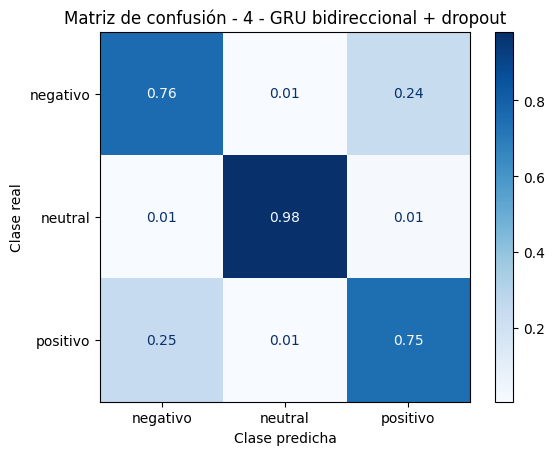

,accuracy,resenas
idioma,,
fr,0.714286,210
es_en,0.727273,33
en,0.739316,234
pt_br,0.742489,233
es,0.857891,1337


380 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
2297,en,negativo,positivo,"Bought this bluetooth speaker for my kitchen last month because my old one died mid-pancake recipe. My daughter uses it for homework music too. I actually returned it once, the first unit had a loose charging port, but the replacement has been just as bad. My husband took it to the garage, came back for it, I ended up buying a second one for him. Honestly, not using it anymore, it just sits there."
17855,es,negativo,positivo,"Compré estos audífonos hace un par de meses y los uso casi a diario para el gimnasio. La nitidez de la imagen no me da ninguna queja, la verdad se ve bien cuando veo videos entre series. Eso sí, al sonido le pondría una sola estrella."
5574,pt_br,positivo,negativo,"Compré essa chapinha pro cabelo da minha filha em março, ela usa todo dia antes da escola. Aqueceu rapidinho e uma vez queimou um pouco o fio dela, então levei na assistência técnica, que trocou uma peça. Cheguei a pensar em devolver, mas no fim não devolvi e continuei usando até hoje. A verdade é que virou item indispensável na nossa rotina, toda semana penso em presentear minha cunhada com uma igual."
5902,fr,positivo,negativo,"Je l'ai commandé au début du mois parce qu'il faisait chaud dans le bureau de la pièce et la livraison est arrivée en trois jours, dans une boîte scellée. Je l'ai branché dès qu'il est arrivé et je l'ai laissé tourner plusieurs après-midis de suite. Le ventilateur a fait mieux que ce à quoi je m'attendais."
7710,es,negativo,positivo,"Me llegó a la casa en unos tres días y lo uso desde hace un rato para el gimnasio, casi todos los días de la semana. La verdad, el soporte técnico fue un error de compra. Eso sí, el botón de encendido cumple de sobra. Ni lo mejor ni lo peor, la verdad ando con la duda."
16350,es,positivo,negativo,"Compré este colchón hace tres meses porque mi espalda ya no aguantaba el viejo. Al principio dudé y casi lo devuelvo, pero al final no lo devolví y sigo usándolo. Mi esposo, que ronca menos ahora (eso dice ella), duerme de un tirón. La verdad, hasta pensé en regalarle el viejo a mi cuñado y lo hice. Enfim, dormimos mejor que antes."
7662,es,negativo,positivo,"Compré este monitor el mes pasado para el setup de mi esposo, que trabaja desde home. La verdad, yo diría que no sea bueno, para nada: los colores look great pero hay bleed en las esquinas y el stand se mueve un poco cuando le pegas al desk. Mi hijo lo usa para sus games y se queja seguido. Para el precio, honestly, no es que me convenza."
13266,fr,positivo,negativo,"La montre connectée suit bien mes pas et l'autonomie tient environ cinq jours, ce que j'apprécie au quotidien. En revanche, l'écran devient presque illisible en plein soleil, et les notifications arrivent parfois avec du retard. D'un côté la légèreté me plaît, de l'autre le bracelet irrite ma peau en fin de journée. Je ne sais toujours pas si je le garde."
16554,es,neutral,negativo,"Compré esta botella a mediados de año y la uso en el gimnasio desde hace meses. Viene en beige, que fue el único color disponible cuando pedí la mía. El envío me llegó en tres días a casa. La capacidad es de un litro y tiene una tapa que se abre con un botón. La llevo en la mochila junto a la toalla cada vez que voy a entrenar por la tarde."
10953,es,positivo,negativo,"Lo compre hace poco por internet y llego en tres dias, lo tengo funcionando sin parar desde que llego. El servicio funciona bastante mal la verdad, no se por que. Aun asi, estoy feliz con la resolucion que me dieron cuando consulte. En fin, ni fu ni fa."


In [111]:
# Cada RNN con su historial y las columnas que recibe (las mejoradas también reciben la última oración)
candidatos = [
    (nombre, historial, modelo, ("text",))
    for (nombre, historial), modelo in zip(
        historiales.items(),
        [model_rnn_1, model_rnn_2, model_rnn_3, model_rnn_4, model_rnn_5],
    )
] + [
    (f"{nombre} (mejorado)", historial, modelo, columnas_2)
    for (nombre, historial), modelo in zip(
        historiales_mejorados.items(),
        [
            model_rnn_1_mejorado,
            model_rnn_2_mejorado,
            model_rnn_3_mejorado,
            model_rnn_4_mejorado,
            model_rnn_5_mejorado,
        ],
    )
]

# La de mejor val_accuracy en la época que restauró la parada temprana
nombre_rnn, _, modelo_rnn, columnas_rnn = max(
    candidatos, key=lambda c: c[1].history["val_accuracy"][c[1].mejor_epoca]
)
print(f"Mejor RNN: {nombre_rnn}")

lotes = tf.data.Dataset.from_tensor_slices(
    entradas_modelo(test_df, columnas_rnn)
).batch(32)
clases_rnn = modelo_rnn.predict(lotes).argmax(axis=1)

errores_rnn = identificar_errores(clases_rnn, test_df, nombre_rnn)

## 4 - Transformers

Para usar transformers, usaremos PyTorch pues este puede usar GPU para correr modelos preentrenados. Comparamos tres
modelos multilingües de 12 capas que entienden las reseñas en español, inglés, francés y portugués (incluidas las
bilingües) sin tener que separarlas por idioma:

| Sección | Modelo                                          | Preentrenamiento                                               |
| ------- | ----------------------------------------------- | -------------------------------------------------------------- |
| 4.1     | `bert-base-multilingual-cased` (mBERT)          | Wikipedia en 104 idiomas                                       |
| 4.2     | `xlm-roberta-base` (XLM-RoBERTa)                | 2,5 TB de texto de CommonCrawl en 100 idiomas                  |
| 4.3     | `cardiffnlp/twitter-xlm-roberta-base-sentiment` | XLM-RoBERTa con tuits, ya ajustado para clasificar sentimiento |

A diferencia de las RNN, un transformer lee la reseña completa a la vez con autoatención: cada palabra mira a todas
las demás. Por eso puede captar por sí solo que la intención de la reseña suele estar en la última oración ("A fin de
cuentas, el rendimiento luce ordinario"), sin darle esa oración como entrada aparte como en la sección 3.2.

Hacemos _fine-tuning_: sobre la salida del primer token se agrega una capa lineal de 3 salidas (negativo, neutral,
positivo) y se reentrena toda la red con una tasa de aprendizaje baja. Todo el código es común a los tres modelos:
para probar otro modelo de Hugging Face basta con pasar su nombre a `entrenar_transformer`.

**GPU en macOS y Windows.** El código elige solo el dispositivo disponible: `cuda` (GPU NVIDIA en Windows/Linux),
`mps` (GPU de Apple Silicon en macOS) o `cpu` si no hay GPU. En Windows, `pip install torch` instala por defecto la
versión **sin** CUDA: para usar la GPU hay que instalar PyTorch con el comando que indica
https://pytorch.org/get-started/locally/ (opción _CUDA_).


In [5]:
# Instala transformers en el kernel activo (igual en macOS, Windows y Colab).
# sentencepiece lo necesita el tokenizador del modelo de Twitter (sección 4.3).
%pip install -q transformers sentencepiece

In [6]:
import gc
import os

# En macOS, las operaciones que MPS aún no soporta se ejecutan en CPU en vez de lanzar un error.
# Debe definirse antes de importar torch.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

from types import SimpleNamespace

import torch
from torch.utils.data import DataLoader
from tqdm import tqdm
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)


def elegir_dispositivo():
    """GPU NVIDIA (Windows/Linux) -> GPU Apple (macOS) -> CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def liberar_memoria_gpu():
    """Devuelve al sistema la memoria de la GPU que PyTorch tenía reservada y ya no usa."""
    gc.collect()
    if dispositivo.type == "cuda":
        torch.cuda.empty_cache()
    elif dispositivo.type == "mps":
        torch.mps.empty_cache()


dispositivo = elegir_dispositivo()
torch.manual_seed(42)
print(f"Dispositivo: {dispositivo}")

Dispositivo: cuda


Reutilizamos la misma división estratificada `train_df` / `test_df` y la misma codificación de etiquetas
`etiqueta_a_id` de las secciones anteriores, para que los resultados sean comparables.

- `cargar_transformer` descarga de Hugging Face el tokenizador y el modelo, con una capa de clasificación de 3 clases.
  Si el modelo no la trae (o trae una con otro número de clases), se crea nueva y aparece un aviso de pesos
  `classifier` _MISSING_ o _MISMATCHED_, que es esperado.
- `dataset_a_torch` es el equivalente de `dataset_a_tf`: tokeniza cada lote con el tokenizador del modelo y lo
  rellena solo hasta la reseña más larga del lote. Cada modelo tiene su propio vocabulario, por eso el tokenizador se
  pasa como argumento. La reseña más larga del conjunto tiene 195 tokens con el tokenizador de mBERT, así que
  `max_length=256` no recorta ninguna.


In [7]:
MAX_TOKENS = 256


def cargar_transformer(nombre_modelo):
    """Tokenizador y modelo `nombre_modelo` de Hugging Face, con una capa de clasificación de 3 clases."""
    tokenizador = AutoTokenizer.from_pretrained(nombre_modelo)
    torch.manual_seed(42)  # la capa nueva se inicializa igual en cada ejecución
    model = AutoModelForSequenceClassification.from_pretrained(
        nombre_modelo,
        num_labels=len(etiquetas),
        id2label=dict(enumerate(etiquetas)),
        label2id=etiqueta_a_id,
        # Si el modelo trae una capa de clasificación con otro número de clases, se reemplaza por una nueva
        ignore_mismatched_sizes=True,
    ).to(dispositivo)
    print(f"{nombre_modelo}: {sum(p.numel() for p in model.parameters()):,} parámetros")
    return tokenizador, model


def tokenizar(textos, tokenizador):
    return tokenizador(
        list(textos),
        padding=True,
        truncation=True,
        max_length=MAX_TOKENS,
        return_tensors="pt",
    )


def dataset_a_torch(df, shuffle, tokenizador, batch_size=16):
    """Lotes de reseñas tokenizadas con su etiqueta en `labels`."""
    ejemplos = list(zip(df["text"], df["label"].map(etiqueta_a_id)))

    def armar_lote(lote):
        textos, ids = zip(*lote)
        entradas = tokenizar(textos, tokenizador)
        entradas["labels"] = torch.tensor(ids)
        return entradas

    # num_workers=0 (valor por defecto): los procesos auxiliares del DataLoader fallan
    # dentro de notebooks en Windows y macOS, así que tokenizamos en el proceso principal.
    return DataLoader(
        ejemplos, batch_size=batch_size, shuffle=shuffle, collate_fn=armar_lote
    )

El entrenamiento sigue la misma lógica que `entrenar_modelo_con_parada_temprana`: se detiene cuando `val_loss` deja
de mejorar durante `patience` épocas y restaura los pesos de la mejor época. Devuelve un objeto con los mismos
atributos que el `History` de Keras (`history` y `mejor_epoca`), para reutilizar `resumir_historiales`.

Los transformers ya vienen preentrenados, así que bastan pocas épocas: usamos `AdamW` con tasa de aprendizaje `2e-5`,
que sube durante el primer 10 % de los pasos y luego baja linealmente a 0. Con tasas más altas el _fine-tuning_ tiende
a borrar lo aprendido en el preentrenamiento.


In [8]:
@torch.no_grad()
def evaluar_transformer(model, loader):
    """Pérdida y accuracy promedio del modelo sobre `loader`."""
    model.eval()
    perdida, aciertos, n = 0.0, 0, 0
    for lote in loader:
        lote = lote.to(dispositivo)
        salida = model(**lote)
        perdida += salida.loss.item() * len(lote["labels"])
        aciertos += (salida.logits.argmax(dim=-1) == lote["labels"]).sum().item()
        n += len(lote["labels"])
    return perdida / n, aciertos / n


def entrenar_transformer_con_parada_temprana(
    model, train_loader, test_loader, max_epochs=4, patience=1, lr=2e-5
):
    optimizador = torch.optim.AdamW(model.parameters(), lr=lr)
    pasos = max_epochs * len(train_loader)
    planificador = get_linear_schedule_with_warmup(optimizador, int(0.1 * pasos), pasos)

    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    mejor_epoca, mejor_estado = 0, None

    for epoca in range(max_epochs):
        model.train()
        perdida, aciertos, n = 0.0, 0, 0
        for lote in tqdm(train_loader, desc=f"Época {epoca + 1}/{max_epochs}"):
            lote = lote.to(dispositivo)
            salida = model(
                **lote
            )  # con `labels`, el modelo calcula la entropía cruzada
            salida.loss.backward()
            optimizador.step()
            planificador.step()
            optimizador.zero_grad()

            perdida += salida.loss.item() * len(lote["labels"])
            aciertos += (salida.logits.argmax(dim=-1) == lote["labels"]).sum().item()
            n += len(lote["labels"])

        val_loss, val_accuracy = evaluar_transformer(model, test_loader)
        for clave, valor in zip(
            history, (perdida / n, aciertos / n, val_loss, val_accuracy)
        ):
            history[clave].append(valor)
        print(
            f"loss = {perdida / n:.4f}, accuracy = {aciertos / n:.4f}, "
            f"val_loss = {val_loss:.4f}, val_accuracy = {val_accuracy:.4f}"
        )

        if val_loss <= min(history["val_loss"]):
            # Copia de los pesos en CPU, equivalente a restore_best_weights=True
            mejor_epoca = epoca
            mejor_estado = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
        elif epoca - mejor_epoca >= patience:
            print(f"Parada temprana en la época {epoca + 1}")
            break

    model.load_state_dict(mejor_estado)
    print(
        f"Mejor época según val_loss: {mejor_epoca + 1} "
        f"(val_loss = {history['val_loss'][mejor_epoca]:.4f}, "
        f"val_accuracy = {history['val_accuracy'][mejor_epoca]:.4f})"
    )
    return SimpleNamespace(history=history, mejor_epoca=mejor_epoca)

`entrenar_transformer` junta todos los pasos para un modelo: lo carga, lo entrena, crea su archivo submission y
predice las clases de `test_df` para la identificación del error. Para el archivo de predicciones reutilizamos
`crear_archivo_predicciones`, que llama a `model.predict` como en Keras: `PredictorTransformer` envuelve al modelo de
PyTorch con ese mismo método. Al terminar, el modelo pasa a la CPU para dejar la GPU libre para el siguiente.


In [9]:
class PredictorTransformer:
    """Adaptador con el `predict` de Keras: recibe los lotes de textos de tf.data que arma
    `crear_archivo_predicciones` y devuelve los logits como arreglo de NumPy."""

    def __init__(self, model, tokenizador):
        self.model = model
        self.tokenizador = tokenizador

    @torch.no_grad()
    def predict(self, lotes):
        self.model.eval()
        logits = []
        for lote in lotes:
            textos = [t.decode("utf-8") for t in lote.numpy()]
            entradas = tokenizar(textos, self.tokenizador).to(dispositivo)
            logits.append(self.model(**entradas).logits.cpu())
        return torch.cat(logits).numpy()


# Los transformers son modelos de PyTorch (Hugging Face), no de Keras, así que no se guardan con
# model.save de Keras: cada uno se sube con push_to_hub a su propio repositorio privado
# <usuario>/proyecto-ml-<nombre_corto> (pesos, configuración y tokenizador), junto con historial.json,
# y se vuelve a cargar con from_pretrained.
def entrenar_o_cargar_transformer(
    nombre_modelo, nombre_corto, crear_loaders, **parametros_entrenamiento
):
    """Carga el transformer de <usuario>/proyecto-ml-<nombre_corto> si ya está en el Hub; si no,
    descarga el modelo base `nombre_modelo`, lo entrena y lo sube. `crear_loaders(tokenizador)`
    devuelve (train_loader, test_loader). Devuelve (tokenizador, modelo, historial)."""
    repo = f"{USUARIO_HF}/proyecto-ml-{nombre_corto}"

    if not REENTRENAR and api.file_exists(repo, "historial.json"):
        tokenizador = AutoTokenizer.from_pretrained(repo)
        model = AutoModelForSequenceClassification.from_pretrained(repo).to(dispositivo)
        historial = descargar_historial(repo, "historial.json")
        print(f"{nombre_corto} cargado de Hugging Face ({resumen_mejor_epoca(historial)})")
        return tokenizador, model, historial

    tokenizador, model = cargar_transformer(nombre_modelo)
    historial = entrenar_transformer_con_parada_temprana(
        model, *crear_loaders(tokenizador), **parametros_entrenamiento
    )
    model.push_to_hub(repo, private=True)
    tokenizador.push_to_hub(repo, private=True)
    # El historial se sube al final: marca que el modelo está completo
    api.upload_file(
        path_or_fileobj=historial_a_json(historial),
        path_in_repo="historial.json",
        repo_id=repo,
        commit_message="Historial de entrenamiento",
    )
    print(f"{nombre_corto} subido a https://huggingface.co/{repo}")
    return tokenizador, model, historial


def entrenar_transformer(nombre_modelo, nombre_corto, **parametros_entrenamiento):
    """Carga, entrena y evalúa el transformer `nombre_modelo` de Hugging Face.

    `parametros_entrenamiento` (p. ej. lr=1e-5 o max_epochs=3) se pasan a
    `entrenar_transformer_con_parada_temprana`. El modelo devuelto queda en la CPU: para volver
    a usarlo, hay que moverlo con `.to(dispositivo)`."""
    tokenizador, model, historial = entrenar_o_cargar_transformer(
        nombre_modelo,
        nombre_corto,
        lambda tok: (
            dataset_a_torch(train_df, shuffle=True, tokenizador=tok),
            dataset_a_torch(test_df, shuffle=False, tokenizador=tok),
        ),
        **parametros_entrenamiento,
    )

    predictor = PredictorTransformer(model, tokenizador)
    submission = crear_archivo_predicciones(
        predictor, dataset_eval, f"submission_{nombre_corto}.csv"
    )

    # Clases predichas en test_df, para la identificación del error
    lotes_test = tf.data.Dataset.from_tensor_slices(test_df["text"].values).batch(32)
    clases_test = predictor.predict(lotes_test).argmax(axis=1)

    model.to("cpu")
    liberar_memoria_gpu()
    return SimpleNamespace(
        model=model,
        tokenizador=tokenizador,
        historial=historial,
        clases_test=clases_test,
        submission=submission,
    )

### 4.1 - BERT multilingüe (mBERT)

`bert-base-multilingual-cased` es un BERT preentrenado con Wikipedia en 104 idiomas. Es nuestra referencia: los otros
dos modelos tienen la misma profundidad (12 capas), así que sus diferencias con mBERT vienen del preentrenamiento y
no de la arquitectura.


In [121]:
mbert = entrenar_transformer("bert-base-multilingual-cased", "mBERT")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


bert-base-multilingual-cased: 177,855,747 parámetros


Época 1/4: 100%|██████████| 1152/1152 [07:08<00:00,  2.69it/s]


loss = 0.4744, accuracy = 0.7456, val_loss = 0.2858, val_accuracy = 0.8530


Época 2/4: 100%|██████████| 1152/1152 [07:09<00:00,  2.68it/s]


... (3 outputs left out)

Época 4/4: 100%|██████████| 1152/1152 [07:08<00:00,  2.69it/s]


loss = 0.1287, accuracy = 0.9336, val_loss = 0.2417, val_accuracy = 0.8813
Parada temprana en la época 4
Mejor época según val_loss: 3 (val_loss = 0.2364, val_accuracy = 0.8828)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en ./modelos/transformers/mBERT
Archivo guardado en ./datos/submission_mBERT.csv (6781 predicciones)
answer
positivo    0.422062
negativo    0.385489
neutral     0.192449
Name: proportion, dtype: float64


In [122]:
mbert.submission

id,answer
0,negativo
1,neutral
2,positivo
3,neutral
4,negativo
5,positivo
6,negativo
7,positivo
8,negativo
9,negativo
10,neutral
11,negativo
12,negativo
13,positivo
14,positivo
15,negativo
16,positivo
17,negativo
18,negativo
19,negativo
20,neutral
21,positivo
22,neutral
23,negativo
24,negativo
25,negativo
26,negativo
27,neutral
28,negativo
29,negativo
30,positivo
31,positivo
32,negativo
33,neutral
34,negativo
35,negativo
36,negativo
37,positivo
38,positivo
39,negativo
40,positivo
41,positivo
42,neutral
43,negativo
44,negativo
45,positivo
46,neutral
47,positivo
48,positivo
49,negativo
50,positivo
51,positivo
52,positivo
53,negativo
54,negativo
55,neutral
56,neutral
57,positivo
58,negativo
59,negativo
60,negativo
61,negativo
62,neutral
63,positivo
64,negativo
65,positivo
66,positivo
67,negativo
68,negativo
69,positivo
70,positivo
71,negativo
72,positivo
73,positivo
74,neutral
75,negativo
76,negativo
77,negativo
78,neutral
79,positivo
80,positivo
81,neutral
82,neutral
83,neutral
84,positi

#### Identificación del error

Repetimos el análisis de la sección 3.3 sobre el mismo `test_df`.


              precision    recall  f1-score   support

    negativo      0.842     0.831     0.836       738
     neutral      1.000     1.000     1.000       560
    positivo      0.835     0.846     0.841       749

    accuracy                          0.883      2047
   macro avg      0.892     0.892     0.892      2047
weighted avg      0.883     0.883     0.883      2047



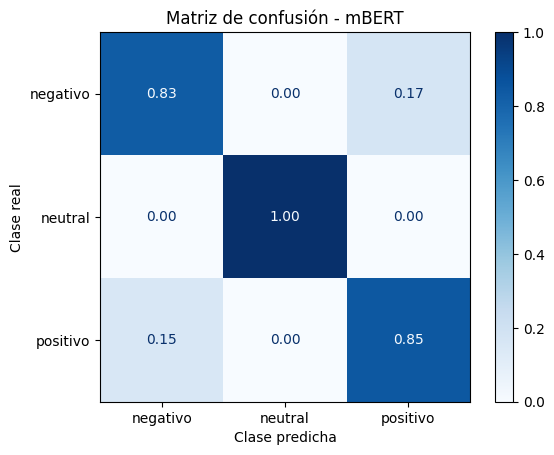

,accuracy,resenas
idioma,,
en,0.841880,234
fr,0.852381,210
pt_br,0.858369,233
es,0.898280,1337
es_en,0.909091,33


240 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
15377,es_en,positivo,negativo,"Este power bank es surprisingly potente, the capacity is just insane, puede cargar mi móvil hasta tres veces sin lag. Sin embargo, the physical quality is very poor; el cable se soltó a la mitad después de solo dos charges. Es un trade-off real. Sé que funciona, but ¿vale la pena el riesgo? I really don't know what to think."
11889,es,positivo,negativo,"Llevando un tiempo con él, lo tengo funcionando sin parar. Lo pedí por internet y me llegó a la casa en unos días, nada raro. El botón de encendido vale totalmente la pena, la verdad ese detalle me gustó harto."
69,es,negativo,positivo,"La compre hace un par de meses y ya con un tiempo de uso, la estoy usando en casa, casi todos los dias en la sala. La app del fabricante me hizo la vida mas facil, la sincronice con el celular sin problema. Eso si, la calidad me decepciono de lo lindo, no me lo esperaba. Cada quien que juzgue."
7794,es,positivo,negativo,"Lo compré para reemplazar otro que ya tenía, más o menos por las mismas fechas de noviembre. Llevo un tiempo con él en casa. Cada peso que pagué por el menú de ajustes valió la pena. Por otro lado, estoy arrepentido de haber comprado el tamaño."
16277,es,positivo,negativo,"Lo compré en una oferta que vi por ahí y llevo un par de meses usándolo casi todos los días en la oficina. La app del fabricante me funciona de maravilla, la uso con los ojos cerrados. Eso sí, la conexión me dio más de un dolor de cabeza, sobre todo las primeras semanas cuando intentaba vincularlo en la casa de mi hermana."
1112,es,positivo,negativo,"Lo compré hace más o menos un mes y lo tengo en la sala de mi casa. El sistema de carga defraudó todas mis expectativas, no esperaba eso. Eso sí, estoy feliz con el tamaño, es justo lo que buscaba para ese espacio. Sopésalo tú mismo, yo no sé qué decirte."
15808,pt_br,positivo,negativo,"Comprei esses fones sem fio no fim do ano passado, uso demais no onibus indo pro trabalho. Tinha um modelo anterior da mesma marca que serviu por tres anos, entao comparei bastante. Na bateria, esses rendem mais que o anterior, duram o dia inteiro sem reclamacao. O som tambem rende mais que o anterior, o grave fica presente sem abafar a voz dos podcast. A caixinha veio amassada de um canto (so o papel, nada demais). Enfim, a expectativa foi batida."
6025,es,positivo,negativo,"Lo pedí un jueves por internet y llegó el lunes siguiente en su caja cerrada. No volvería a comprar la relación calidad-precio ni regalado. Lo tengo desde entonces en el escritorio del cuarto, donde lo uso un rato casi todas las noches. La terminación superó todas mis expectativas. Hay de todo, como se ve."
12784,en,negativo,positivo,"I got this smartwatch in March for my morning runs, my wife uses it too for tracking sleep. Compared to my old model, this one lasts shorter and syncs slower with the phone, the previous one actually handled notifications better. The truth is I barely wear it anymore, even my daughter borrowed it once for her gym class and gave it back after a day."
1495,es,negativo,positivo,"Me llego el frasco un martes, dos dis despues de pedirlo, y en general el empaque venia bien cerrado. La tapa se queda muy corto. Lo uso en la cocina casi a diario desde entonces. Termine feliz con el boton de encendido. Ni lo mejor ni lo peor, la verdad."


In [123]:
errores_mbert = identificar_errores(mbert.clases_test, test_df, "mBERT")

### 4.2 - XLM-RoBERTa

`xlm-roberta-base` es un RoBERTa multilingüe preentrenado con 2,5 TB de texto de CommonCrawl en 100 idiomas. Comparado
con mBERT, se preentrenó con muchos más datos por idioma (mBERT solo usó Wikipedia), con un vocabulario más grande
(250.000 piezas) y solo con la tarea de predecir palabras ocultas, por lo que suele clasificar mejor texto multilingüe.


In [124]:
xlm_roberta = entrenar_transformer("xlm-roberta-base", "XLM-RoBERTa")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

... (9 outputs left out)

Época 4/4: 100%|██████████| 1152/1152 [07:31<00:00,  2.55it/s]


loss = 0.1235, accuracy = 0.9307, val_loss = 0.1810, val_accuracy = 0.8964
Parada temprana en la época 4
Mejor época según val_loss: 3 (val_loss = 0.1700, val_accuracy = 0.8999)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en ./modelos/transformers/XLM-RoBERTa
Archivo guardado en ./datos/submission_XLM-RoBERTa.csv (6781 predicciones)
answer
negativo    0.448311
positivo    0.361156
neutral     0.190532
Name: proportion, dtype: float64


In [125]:
xlm_roberta.submission

id,answer
0,negativo
1,neutral
2,negativo
3,neutral
4,negativo
5,positivo
6,negativo
7,positivo
8,negativo
9,negativo
10,neutral
11,negativo
12,negativo
13,negativo
14,positivo
15,negativo
16,negativo
17,negativo
18,negativo
19,negativo
20,neutral
21,positivo
22,neutral
23,negativo
24,negativo
25,negativo
26,negativo
27,neutral
28,negativo
29,negativo
30,positivo
31,positivo
32,negativo
33,neutral
34,negativo
35,negativo
36,negativo
37,positivo
38,positivo
39,negativo
40,positivo
41,positivo
42,neutral
43,negativo
44,negativo
45,positivo
46,neutral
47,negativo
48,positivo
49,negativo
50,positivo
51,positivo
52,positivo
53,negativo
54,negativo
55,neutral
56,neutral
57,positivo
58,positivo
59,negativo
60,positivo
61,negativo
62,neutral
63,positivo
64,negativo
65,positivo
66,positivo
67,negativo
68,negativo
69,negativo
70,positivo
71,negativo
72,positivo
73,positivo
74,neutral
75,negativo
76,negativo
77,negativo
78,neutral
79,positivo
80,negativo
81,neutral
82,neutral
83,neutral
84,positi

#### Identificación del error

Repetimos el análisis de la sección 3.3 sobre el mismo `test_df`.


              precision    recall  f1-score   support

    negativo      0.826     0.915     0.868       738
     neutral      1.000     1.000     1.000       560
    positivo      0.906     0.810     0.856       749

    accuracy                          0.900      2047
   macro avg      0.911     0.908     0.908      2047
weighted avg      0.903     0.900     0.900      2047



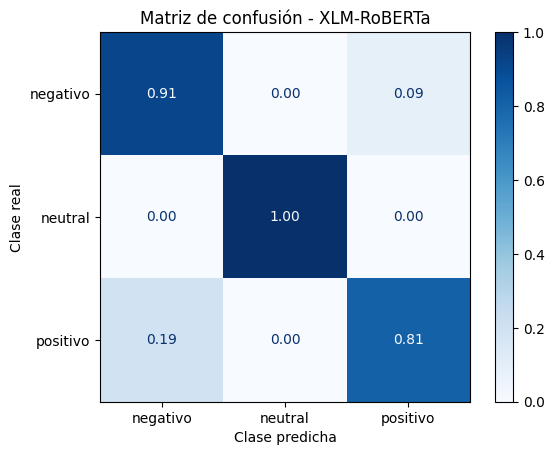

,accuracy,resenas
idioma,,
es_en,0.787879,33
fr,0.842857,210
es,0.908003,1337
pt_br,0.909871,233
en,0.910256,234


205 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
14343,es,positivo,negativo,"Lo compré a mediados de mes por internet y me llegó en cuatro días en su caja. El acabado no es para nada lo que esperaba. Lo uso en la recámara, conectado a la red de casa. La señal fue todo un acierto. Lo tengo con su garantía de un año guardada en el cajón. En fin, ni fu ni fa."
357,es,positivo,negativo,"La compre a mediados de ano porque la vi en una promo y llegue a dudar un buen rato antes de pedirlo. Siento que tire el dinero con la construccion. Por cierto, recomiendo la correa con los ojos cerrados. La uso casi a diario en las salidas del parque, asi que ya le agarre el ritmo a las dos cosas. Ni tan bueno ni tan malo."
20376,fr,positivo,negativo,"Je l'ai commandé à la mi-mois et il est arrivé en trois jours, dans un emballage scellé. Le service laisse vraiment à désirer, franchement. La portabilité, c'est exactement ce que je cherchais. J'ai des sentiments mitigés là-dessus, je ne sais pas trop quoi en penser encore."
16410,es,negativo,positivo,"Se lo compre a un familiar hace un par de meses, mas o menos por octubre, y le puse pilas nuevas antes de entregarselo. La verdad no volveria a comprar el empaque ni regalado. El aparato lo dejamos en la cocina, donde se usa un rato casi todos los dias. De todas formas el procesador funciona de maravilla."
2765,pt_br,positivo,negativo,"Uso as zapatilhas para correr há três semanas. O amortecimento no calcanhar é excelente e me ajudou com a dor que sentia depois dos treinos longos. Por outro lado, o cabedal aperta demais na largura do pé, mesmo depois de amaciar, e em dias quentes isso incomoda bastante. Não sei bem se vou manter o uso ou procurar outro modelo, porque o conforto na sola não compensa totalmente o desconforto na parte de cima. Fico em dúvida."
15004,es_en,positivo,negativo,"Compré este set de sartenes el mes pasado y la verdad es que I have mixed feelings. El antiadherente funciona perfecto, los huevos slide right off sin aceite, eso me encanta. Pero el mango se calienta muchísimo, I have to use un trapo every time y eso es un problema real. El tamaño del más grande está perfecto para mi familia, aunque las asas no son removibles. No sé si las volvería a comprar, honestly I'm still deciding."
4128,fr,negativo,positivo,"Je l'ai commandé à la mi-mois et il est arrivé en quatre jours chez moi. Je l'ai utilisé au début dans le jardin, rien d'exceptionnel comme contexte. Le moteur m'a agréablement surpris. Au passage, le chargeur a déçu toutes mes attentes, et pourtant il venait dans le même carton."
8176,fr,positivo,negativo,"La plaque chauffe très vite et glisse bien sur mes cheveux épais, c'est indéniable. Par contre, le fil est court et l'écran de température s'éteint tout seul pendant l'utilisation, ce qui m'oblige à vérifier sans arrêt. Je ne sais pas encore si je la garde, je dois voir comment elle tient dans quelques semaines."
5543,es,negativo,positivo,"Lo pedí a finales de mes y llegó en tres días a mi casa, en una caja común sin nada raro. Siento que tiré el dinero con la construcción. Lo vengo usando en el escritorio desde entonces, unas horas al día. El cable respondió tal como esperaba."
11308,es,negativo,positivo,"Compré este teclado mecánico en marzo para trabajar desde casa, porque mis dedos ya estaban sufriendo con el de membrana del trabajo. La verdad, escribir con él es un gustazo, cada tecla responde con ese clic tan satisfactorio que suena tan fuerte que mi hermana me pidió que lo guardara al tercer día. Lo uso unas ocho horas diarias y las muñecas me duelen más que antes por lo duro del pulleo. Un detalle: llegó sin el cable que anunciaban, ese toque se agradece. En fin, no esperaba tanto por el precio."


In [126]:
errores_xlm_roberta = identificar_errores(
    xlm_roberta.clases_test, test_df, "XLM-RoBERTa"
)

### 4.3 - XLM-RoBERTa ajustado para sentimiento en Twitter

`cardiffnlp/twitter-xlm-roberta-base-sentiment` es XLM-RoBERTa con un preentrenamiento adicional en unos 198 millones
de tuits multilingües, ajustado después para clasificar sentimiento en ocho idiomas, entre ellos español, inglés,
francés y portugués. Sus tres clases (_negative_, _neutral_, _positive_) están en el mismo orden que las nuestras, así
que se reutiliza su capa de clasificación ya entrenada (no aparece el aviso _MISSING_) y el _fine-tuning_ parte de un
modelo que ya distingue sentimientos. La pregunta es si lo aprendido con tuits, que son textos cortos e informales,
sirve para reseñas de productos.


In [127]:
twitter = entrenar_transformer(
    "cardiffnlp/twitter-xlm-roberta-base-sentiment", "XLM-RoBERTa-Twitter"
)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (9 outputs left out)

Época 3/4: 100%|██████████| 1152/1152 [07:31<00:00,  2.55it/s]


loss = 0.1440, accuracy = 0.9196, val_loss = 0.1722, val_accuracy = 0.8964
Parada temprana en la época 3
Mejor época según val_loss: 2 (val_loss = 0.1701, val_accuracy = 0.8999)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en ./modelos/transformers/XLM-RoBERTa-Twitter
Archivo guardado en ./datos/submission_XLM-RoBERTa-Twitter.csv (6781 predicciones)
answer
positivo    0.44315
negativo    0.36617
neutral     0.19068
Name: proportion, dtype: float64


In [128]:
twitter.submission

id,answer
0,negativo
1,neutral
2,positivo
3,neutral
4,negativo
5,positivo
6,negativo
7,positivo
8,negativo
9,negativo
10,neutral
11,negativo
12,negativo
13,positivo
14,positivo
15,negativo
16,positivo
17,negativo
18,negativo
19,positivo
20,neutral
21,positivo
22,neutral
23,negativo
24,negativo
25,negativo
26,positivo
27,neutral
28,negativo
29,negativo
30,positivo
31,positivo
32,negativo
33,neutral
34,negativo
35,negativo
36,negativo
37,positivo
38,positivo
39,negativo
40,positivo
41,positivo
42,neutral
43,negativo
44,negativo
45,positivo
46,neutral
47,positivo
48,positivo
49,negativo
50,positivo
51,positivo
52,positivo
53,negativo
54,negativo
55,neutral
56,neutral
57,positivo
58,positivo
59,positivo
60,negativo
61,negativo
62,neutral
63,positivo
64,negativo
65,positivo
66,positivo
67,negativo
68,positivo
69,negativo
70,positivo
71,negativo
72,positivo
73,positivo
74,neutral
75,negativo
76,negativo
77,negativo
78,neutral
79,positivo
80,negativo
81,neutral
82,neutral
83,neutral
84,positi

#### Identificación del error

Repetimos el análisis de la sección 3.3 sobre el mismo `test_df`.


              precision    recall  f1-score   support

    negativo      0.897     0.817     0.855       738
     neutral      0.998     1.000     0.999       560
    positivo      0.834     0.907     0.869       749

    accuracy                          0.900      2047
   macro avg      0.910     0.908     0.908      2047
weighted avg      0.902     0.900     0.900      2047



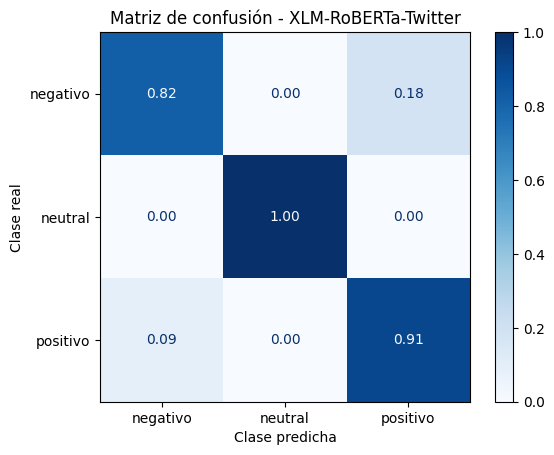

,accuracy,resenas
idioma,,
fr,0.880952,210
en,0.888889,234
es,0.899028,1337
es_en,0.909091,33
pt_br,0.931330,233


205 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
8660,fr,positivo,negativo,"Le son sur les basses est franchement impressionnant pour ce prix, et la batterie tient vraiment la semaine. Mais les aigus grincent un peu quand je monte le volume, et le plastique fait cheap sous la main. Les deux défauts m'agacent autant que les qualités me plaisent, honnêtement je ne sais pas encore si je le garde."
10605,es,negativo,positivo,"Compré esto en enero porque estaba en oferta y llegó en tres días a mi casa. Siento que tiré el dinero con la portabilidad. Lo uso ahora en la oficina casi todos los días, más que nada en las mañanas. La tapa fue todo un acierto. Ahí lo dejo."
9278,es,negativo,positivo,"Me llegó el jueves por la tarde, lo compré para el cuarto de mi hermana porque necesitábamos uno ahí. La calidad se dañó antes de lo que esperaba, la verdad. Eso sí, la pantalla táctil la recomiendo con los ojos cerrados, para lo que la usamos va sobrada. No sabría bien qué recomendar, la neta."
19262,fr,positivo,negativo,"L'image est superbe, colors fideles et contraste vraiment agréable pour mes sessions de retouche photo. En revanche, le pied est instable et l'écran vacille dès que je bouge le bureau, ce qui agace au quotidien. Je ne sais toujours pas si je le garde ou si je le renvoie, il me faudrait quelques semaines encore pour trancher."
7097,es,negativo,positivo,"El monitor llegó antes de lo previsto y la calidad de imagen para editar fotos me parece muy sólida, los colores se ven fieles. Ahora bien, los biseles se ensucian de polvo con una facilidad increíble y el menú de botones es un desastre para navegar. Llevo tres semanas usándolo y todavía no me decido si lo que gano en pantalla compensa lo que pierdo en comodidad. Sigo pensándolo."
19477,es,negativo,positivo,"Compré esta memoria a mediados de marzo por internet, llegó en tres días hábiles a mi casa. La uso en la laptop para respaldar fotos de la familia. Estoy arrepentido de haber comprado la memoria. Por otro lado, la resistencia al agua me hizo la vida más fácil, porque la llevo en la mochila cuando salgo a caminar con los niños los domingos. Así que ahí lo dejo."
9662,es,negativo,positivo,"Lo compré un martes por la tarde y me llegó al día siguiente en un paquete bastante sencillo. Por si a alguien le sirve de referencia, soy de Monterrey y lo uso en la alberca del complejo donde vivo. La resistencia al agua no es para nada lo que esperaba. La batería trae 200 mAh según la caja y llegó con su cable de carga. Le pondría cinco estrellas a la conexión. Ni lo mejor ni lo peor."
7503,en,positivo,negativo,"I bought it in the middle of the year because the one my phone came with had already broken, and it arrived at my place in four days. I wouldn't recommend the case to anyone, honestly. As for the phone itself, I'd buy it again without thinking twice. I use it every day to take my phone to work and nothing more."
8776,es,negativo,positivo,"Lo pedí un martes y me llegó al día siguiente en la sucursal que tengo a dos cuadras de la oficina. Lo usé esa misma semana cuando fui de visita a casa de mi hermana. Me decepcionó el tamaño de principio a fin. Por otro lado, el empaque cumple de sobra."
9986,es,positivo,negativo,"Hace un mes, se lo compre a un familiar. Termine fliz con la calidad. De paso, el cargador me dio mas de un dolor de cabeza."


In [129]:
errores_twitter = identificar_errores(
    twitter.clases_test, test_df, "XLM-RoBERTa-Twitter"
)

### 4.4 - Comparación de todos los modelos

Comparamos los tres transformers con todas las RNN usando `resumir_historiales`. Después contamos cuántas reseñas de
`test_df` falla cada transformer y cuántas de ellas también falla la mejor RNN (sección 3.3). Si todos los modelos
fallan casi las mismas reseñas, el problema probablemente está en esas reseñas (por ejemplo, etiquetas ambiguas) y no
en la arquitectura.


In [130]:
transformers_entrenados = {
    "mBERT": mbert,
    "XLM-RoBERTa": xlm_roberta,
    "XLM-RoBERTa-Twitter": twitter,
}

pd.concat(
    [
        resumir_historiales(historiales),
        resumir_historiales(historiales_mejorados).assign(
            modelo=lambda d: d["modelo"] + " (mejorado)"
        ),
        resumir_historiales(
            {n: r.historial for n, r in transformers_entrenados.items()}
        ),
    ]
).sort_values("val_accuracy", ascending=False)

,modelo,mejor_epoca,val_accuracy,val_loss,train_accuracy
1,XLM-RoBERTa,3,0.899853,0.169989,0.914708
2,XLM-RoBERTa-Twitter,2,0.899853,0.170136,0.900157
0,mBERT,3,0.882755,0.236428,0.907378
3,4 - GRU bidireccional + dropout,2,0.814362,0.330486,0.822955
4,5 - LSTM bidireccionales apiladas,3,0.804592,0.351309,0.834464
3,4 - GRU bidireccional + dropout (mejorado),2,0.800684,0.343948,0.829307
2,3 - LSTM,2,0.800195,0.349475,0.846354
4,5 - LSTM bidireccionales apiladas (mejorado),2,0.793845,0.343551,0.826646
2,3 - LSTM (mejorado),2,0.791402,0.359451,0.825343
1,2 - SimpleRNN apiladas,2,0.778212,0.417577,0.820186


In [131]:
# Índices de las reseñas de test_df mal clasificadas por cada modelo
fallas_rnn = set(errores_rnn.index)
fallas = {
    "mBERT": set(errores_mbert.index),
    "XLM-RoBERTa": set(errores_xlm_roberta.index),
    "XLM-RoBERTa-Twitter": set(errores_twitter.index),
}

print(f"La mejor RNN falla {len(fallas_rnn)} reseñas.")
print(
    f"Reseñas que fallan la mejor RNN y los tres transformers: {len(fallas_rnn.intersection(*fallas.values()))}"
)

pd.DataFrame(
    {
        "errores": {n: len(f) for n, f in fallas.items()},
        "también los falla la RNN": {n: len(f & fallas_rnn) for n, f in fallas.items()},
        "solo los falla el transformer": {
            n: len(f - fallas_rnn) for n, f in fallas.items()
        },
    }
)

La mejor RNN falla 380 reseñas.
Reseñas que fallan la mejor RNN y los tres transformers: 40


,errores,también los falla la RNN,solo los falla el transformer
mBERT,240,119,121
XLM-RoBERTa,205,106,99
XLM-RoBERTa-Twitter,205,99,106


## 4.5 - RoBERTa con la última oración explícita


In [132]:
def tokenizar_con_ultima(textos, ultimas, tokenizador):
    """Tokeniza pares (última oración, reseña). El tokenizador los une como
    [CLS] última oración [SEP] reseña [SEP], así el modelo ve la última oración por separado.
    """
    return tokenizador(
        list(ultimas),
        list(textos),
        padding=True,
        truncation="only_second",  # si hiciera falta recortar, se recorta la reseña, no la última oración
        max_length=MAX_TOKENS,
        return_tensors="pt",
    )


def dataset_a_torch_con_ultima(df, shuffle, tokenizador, batch_size=16):
    """Igual que `dataset_a_torch`, pero cada ejemplo es el par (última oración, reseña)."""
    ejemplos = list(zip(df["text"], df["ultima"], df["label"].map(etiqueta_a_id)))

    def armar_lote(lote):
        textos, ultimas, ids = zip(*lote)
        entradas = tokenizar_con_ultima(textos, ultimas, tokenizador)
        entradas["labels"] = torch.tensor(ids)
        return entradas

    return DataLoader(
        ejemplos, batch_size=batch_size, shuffle=shuffle, collate_fn=armar_lote
    )


class PredictorTransformerConUltima(PredictorTransformer):
    """Como `PredictorTransformer`, pero recibe los lotes {"text", "ultima"} que arma
    `crear_archivo_predicciones` con `columnas=columnas_2`."""

    @torch.no_grad()
    def predict(self, lotes):
        self.model.eval()
        logits = []
        for lote in lotes:
            textos = [t.decode("utf-8") for t in lote["text"].numpy()]
            ultimas = [t.decode("utf-8") for t in lote["ultima"].numpy()]
            entradas = tokenizar_con_ultima(textos, ultimas, self.tokenizador).to(
                dispositivo
            )
            logits.append(self.model(**entradas).logits.cpu())
        return torch.cat(logits).numpy()


def entrenar_transformer_con_ultima(
    nombre_modelo, nombre_corto, **parametros_entrenamiento
):
    """Igual que `entrenar_transformer`, pero el modelo recibe la última oración como entrada aparte."""
    tokenizador, model, historial = entrenar_o_cargar_transformer(
        nombre_modelo,
        nombre_corto,
        lambda tok: (
            dataset_a_torch_con_ultima(train_df, shuffle=True, tokenizador=tok),
            dataset_a_torch_con_ultima(test_df, shuffle=False, tokenizador=tok),
        ),
        **parametros_entrenamiento,
    )

    predictor = PredictorTransformerConUltima(model, tokenizador)
    submission = crear_archivo_predicciones(
        predictor,
        dataset_eval,
        f"submission_{nombre_corto}.csv",
        columnas=columnas_2,
    )

    lotes_test = tf.data.Dataset.from_tensor_slices(
        entradas_modelo(test_df, columnas_2)
    ).batch(32)
    clases_test = predictor.predict(lotes_test).argmax(axis=1)

    model.to("cpu")
    liberar_memoria_gpu()
    return SimpleNamespace(
        model=model,
        tokenizador=tokenizador,
        historial=historial,
        clases_test=clases_test,
        submission=submission,
    )

In [ ]:
twitter_ultima = entrenar_transformer_con_ultima(
    "xlm-roberta-base", "XLM-RoBERTa_ultima"
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


xlm-roberta-base: 278,045,955 parámetros


Época 1/4: 100%|██████████| 1152/1152 [08:55<00:00,  2.15it/s]


loss = 0.4106, accuracy = 0.8020, val_loss = 0.1833, val_accuracy = 0.8935


Época 2/4: 100%|██████████| 1152/1152 [08:57<00:00,  2.14it/s]


... (3 outputs left out)

Época 4/4: 100%|██████████| 1152/1152 [08:56<00:00,  2.15it/s]


loss = 0.1168, accuracy = 0.9375, val_loss = 0.1862, val_accuracy = 0.8925
Parada temprana en la época 4
Mejor época según val_loss: 3 (val_loss = 0.1696, val_accuracy = 0.9023)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en ./modelos/transformers/XLM-RoBERTa-Twitter_ultima
Archivo guardado en ./datos/submission_XLM-RoBERTa-Twitter_ultima.csv (6781 predicciones)
answer
negativo    0.452146
positivo    0.357174
neutral     0.190680
Name: proportion, dtype: float64


#### Identificación del error


              precision    recall  f1-score   support

    negativo      0.815     0.943     0.874       738
     neutral      1.000     1.000     1.000       560
    positivo      0.934     0.789     0.855       749

    accuracy                          0.902      2047
   macro avg      0.916     0.911     0.910      2047
weighted avg      0.909     0.902     0.902      2047



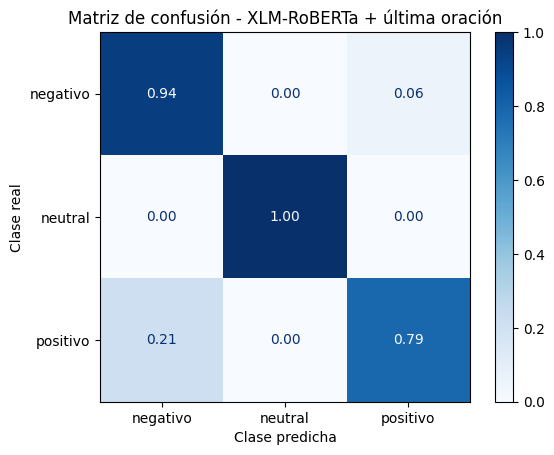

,accuracy,resenas
idioma,,
es_en,0.818182,33
fr,0.857143,210
pt_br,0.896996,233
es,0.908751,1337
en,0.923077,234


200 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
16277,es,positivo,negativo,"Lo compré en una oferta que vi por ahí y llevo un par de meses usándolo casi todos los días en la oficina. La app del fabricante me funciona de maravilla, la uso con los ojos cerrados. Eso sí, la conexión me dio más de un dolor de cabeza, sobre todo las primeras semanas cuando intentaba vincularlo en la casa de mi hermana."
4319,fr,positivo,negativo,"Le chargeur tient vraiment ses promesses côté autonomie, il m'a dépanné deux jours complets en voyage, et il recharge vite. Mais il pèse lourd dans le sac, on le sent tout de suite, et le câble fourni semble fragile après quelques semaines. Je ne sais pas si l'encombrement compense ce qu'il apporte, ça dépend vraiment de l'usage de chacun et j'hésite encore."
20003,es,positivo,negativo,"La compré hace un par de semanas por internet y me llegó en tres días. La uso para el gimnasio, la llevo en la mochila a diario. La tapa no vale lo que cuesta, la verdad. Por otro lado, recomiendo la conexión con los ojos cerrados. Lo dejo a tu criterio."
8489,es,positivo,negativo,"Me llegó a mediados de mes, lo compré en línea y tardó como cuatro días en llegar. La verdad, el acabado no vale lo que cuesta. Aun así lo he estado usando todos los días en la oficina, porque la señal superó todas mis expectativas. La verdad tengo sentimientos encontrados."
4913,es,negativo,positivo,"Compré esto a mediados de año porque andaba necesitando uno para la casa de mi hermana, llegó en unos cuatro días. La verdad, cada peso que pagué por la señal valió la pena. Eso sí, el diseño no es para nada lo que esperaba. Yo lo conecto en la sala y mi hermana lo usa en su cuarto, y los dos coincidimos en que ni tan bueno ni tan malo."
19836,es,positivo,negativo,"Me llego el miercoles por la tarde, dos dias despues de pedirlo, en una caja sencilla. Lo uso en el escritorio de la casa, mas que nada por las tardes. La comodidad esta muy por debajo de la media, la verdad. Por otro lado, el menu de ajustes respondio tal como esperaba. Sopesalo tu mismo."
4538,es,positivo,negativo,"Compré esto a mediados de año por internet y llegó en unos días sin contratiempos. La batería me hizo la vida más fácil desde que empecé a usarla en mis salidas cotidianas. Eso sí, con la resistencia al agua no paré de tener problemas desde el primer mes. Así que ahí lo dejo."
3718,pt_br,negativo,positivo,"A fritadeira elétrica sem óleo esquenta rápido e as batatas ficam crocantes de verdade, o que eu gostei bastante. Por outro lado, o cesto é pequeno demais para uma família, acabei fazendo dois lotes no mesmo jantar. O painel é simples, mas o barulho incomoda um pouco. Fico em dúvida se o espaço que ela ocupa na bancada compensa, ainda não me decidi sobre ficar com ela."
5455,es,positivo,negativo,"Compré esto en línea y me llegó en unos cinco días, en su caja tal cual. La uso en casa casi a diario desde que la recibí. La verdad no pare de tener problemas con el sonido desde el primer día que la prendí. Eso sí, la cámara me hizo la vida mas facil para lo que la necesito. Queda a criterio de cada uno, yo nomás cuento mi experiencia."
12570,es,negativo,positivo,"Compre este microfono un sabado por la tarde en una tienda cerca de mi casa, me lo llevaron en la moto y llegue antes de que cerrara. Cada peso que pague por el microfono valio la pena. Por otro lado, el control remoto me dio mas de un dolor de cabeza, lo tuve que estar configurando un rato esa misma noche. La verdad, ni lo mejor ni lo peor, ahi lo dejo."


,modelo,mejor_epoca,val_accuracy,val_loss,train_accuracy
0,XLM-RoBERTa-Twitter,2,0.899853,0.170136,0.900157
1,XLM-RoBERTa-Twitter + última oración,3,0.902296,0.169566,0.920571


: 

In [ ]:
errores_twitter_ultima = identificar_errores(
    twitter_ultima.clases_test, test_df, "XLM-RoBERTa + última oración"
)

# Comparación con el mismo modelo sin la última oración
resumir_historiales(
    {
        "XLM-RoBERTa": twitter.historial,
        "XLM-RoBERTa+ última oración": twitter_ultima.historial,
    }
)